# Legal Document Summariser
Contract PDF → key details, red-flag clauses (rules + fine-tuned Legal-BERT) and a BART summary.

## Setup

In [1]:
import os, sys, json, shutil

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_DIR = '/content/legal_doc_summariser' if IN_COLAB else os.path.join(os.getcwd(), 'legal_doc_summariser')
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
MODEL_DIR = os.path.join(PROJECT_DIR, 'models')
CLF_DIR = os.path.join(MODEL_DIR, 'legal_bert_clause_clf')       # fine-tuned Legal-BERT + clf_meta.json
SAMPLE_DIR = os.path.join(PROJECT_DIR, 'sample_contracts')
REPORT_DIR = os.path.join(PROJECT_DIR, 'reports')
REVIEW_DIR = os.path.join(PROJECT_DIR, 'review_sheets')
FIG_DIR = os.path.join(PROJECT_DIR, 'figures')
for d in [DATA_DIR, MODEL_DIR, SAMPLE_DIR, REPORT_DIR, REVIEW_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)
sys.path.insert(0, PROJECT_DIR)   # so legal_nlp_utils / legal_pipeline / synthetic_check can be imported once written

CUAD_JSON_URL = "https://huggingface.co/datasets/theatticusproject/cuad/resolve/main/CUAD_v1/CUAD_v1.json"
CUAD_JSON = os.path.join(DATA_DIR, 'CUAD_v1.json')
SEED = 42

print("Running on Colab:", IN_COLAB)
print("Project directory:", PROJECT_DIR)

Running on Colab: False
Project directory: /Users/neeharikapai/small_projects/nlpproject/legal_doc_summariser


In [2]:
!{sys.executable} -m pip install -q requests torch pandas numpy matplotlib datasets transformers scikit-learn tqdm pdfplumber PyMuPDF spacy rouge_score gradio
import spacy
if not spacy.util.is_package('en_core_web_sm'):
    !{sys.executable} -m spacy download en_core_web_sm -q


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
import re, time, random, gc, hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
from tqdm.auto import tqdm
from IPython.display import Markdown, display
from sklearn.metrics import precision_recall_fscore_support, precision_recall_curve
from transformers import AutoTokenizer, AutoModelForSequenceClassification

pd.set_option('display.max_colwidth', 150)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda'); print("Using NVIDIA GPU:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps'); print("Using Apple Silicon GPU (MPS)")
else:
    DEVICE = torch.device('cpu'); print("Using CPU")
SUMMARIZER_MODEL = 'facebook/bart-large-cnn' if DEVICE.type != 'cpu' else 'sshleifer/distilbart-cnn-12-6'

Using Apple Silicon GPU (MPS)


# Part 1: Data preparation

## 1.1 Load CUAD

In [4]:
if not os.path.exists(CUAD_JSON):
    print("Downloading CUAD_v1.json (~40MB, may take a minute)...")
    response = requests.get(CUAD_JSON_URL, timeout=300)
    response.raise_for_status()  # will raise clearly if the URL ever changes again
    with open(CUAD_JSON, 'wb') as f:
        f.write(response.content)

with open(CUAD_JSON) as f:
    cuad_raw = json.load(f)
print("Number of contracts (titles):", len(cuad_raw['data']))

Number of contracts (titles): 510


In [5]:
# Inspect one contract's structure
sample_contract = cuad_raw['data'][0]
print("Title:", sample_contract['title'])
print("Number of paragraphs:", len(sample_contract['paragraphs']))

sample_para = sample_contract['paragraphs'][0]
print("Context preview:", sample_para['context'][:300])
print()
print("Number of QA pairs (clause categories asked):", len(sample_para['qas']))
print("Example QA pair:", json.dumps(sample_para['qas'][0], indent=2)[:500])

Title: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Number of paragraphs: 1
Context preview: EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999.

        

Number of QA pairs (clause categories asked): 41
Example QA pair: {
  "answers": [
    {
      "text": "DISTRIBUTOR AGREEMENT",
      "answer_start": 44
    }
  ],
  "id": "LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Document Name",
  "question": "Highlight the parts (if any) of this contract related to \"Document Name\" that should be reviewed by a lawyer. Details: The name of the contract",
  "is_impossible": false
}


## 1.2 Clause-level table

In [6]:
def flatten_cuad(cuad_raw):
    rows = []
    for entry in cuad_raw['data']:
        title = entry['title']
        for para in entry['paragraphs']:
            context = para['context']
            for qa in para['qas']:
                category_match = re.search(r'"([^"]+)"', qa['question'])
                category = category_match.group(1) if category_match else qa['question'][:40]
                answer_texts = [a['text'] for a in qa.get('answers', [])]
                answer_spans = [(a['answer_start'], a['answer_start'] + len(a['text'])) for a in qa.get('answers', []) if a['text'].strip()]
                rows.append({
                    'contract_id': title,
                    'context': context,
                    'category': category,
                    'answers': answer_texts,
                    'answer_spans': answer_spans,
                })
    return rows

cuad_rows = flatten_cuad(cuad_raw)
print("Total (contract, category) rows:", len(cuad_rows))
print("Example row:", {k: (v[:150] if isinstance(v, str) else v) for k, v in cuad_rows[0].items()})

Total (contract, category) rows: 20910
Example row: {'contract_id': 'LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT', 'context': 'EXHIBIT 10.6\n\n                              DISTRIBUTOR AGREEMENT\n\n         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between El', 'category': 'Document Name', 'answers': ['DISTRIBUTOR AGREEMENT'], 'answer_spans': [(44, 65)]}


In [7]:
# Sentence boundaries only (fast spaCy pipeline)
import spacy
nlp = spacy.load("en_core_web_sm", exclude=["tagger", "parser", "ner", "lemmatizer", "attribute_ruler", "tok2vec", "senter"])
nlp.add_pipe("sentencizer")
nlp.max_length = 3_000_000

def build_clause_level_df(cuad_rows, max_contracts=None):
    """Splits each contract into sentences and labels each with the categories whose answer span overlaps it."""
    contracts = {}
    for row in cuad_rows:
        key = row['contract_id']
        if key not in contracts:
            contracts[key] = {'context': row['context'], 'spans': []}
        contracts[key]['spans'] += [(row['category'], s, e) for s, e in row['answer_spans']]

    keys = list(contracts.keys())[:max_contracts] if max_contracts else list(contracts.keys())
    clause_rows = []
    for contract_id, doc in zip(keys, nlp.pipe((contracts[k]['context'] for k in keys), batch_size=8)):
        spans = contracts[contract_id]['spans']
        for sent in doc.sents:
            text = sent.text.strip()
            if not text:
                continue
            start, end = sent.start_char, sent.end_char
            labels = {cat for cat, s, e in spans if s < end and e > start}
            clause_rows.append({'contract_id': contract_id, 'clause_text': text, 'labels': sorted(labels)})
    return pd.DataFrame(clause_rows)

clause_df = build_clause_level_df(cuad_rows, max_contracts=None)
print("Total clauses:", len(clause_df))
print("Clauses with at least one risk label:", (clause_df['labels'].apply(len) > 0).sum())
clause_df.to_pickle(os.path.join(DATA_DIR, 'cuad_clause_level.pkl'))
print("Saved to", os.path.join(DATA_DIR, 'cuad_clause_level.pkl'))

Total clauses: 116497
Clauses with at least one risk label: 10146
Saved to /Users/neeharikapai/small_projects/nlpproject/legal_doc_summariser/data/cuad_clause_level.pkl


## 1.3 Exploratory data analysis

In [8]:
all_labels = [label for labels in clause_df['labels'] for label in labels]
label_counts = Counter(all_labels)

label_df = pd.DataFrame(label_counts.items(), columns=['category', 'count']).sort_values('count', ascending=False)
print(f"Number of distinct categories present: {len(label_df)}")
label_df.head(20)

Number of distinct categories present: 41


,category,count
2,Parties,913
4,License Grant,807
20,Cap On Liability,699
19,Audit Rights,677
13,Insurance,660
11,Anti-Assignment,655
1,Document Name,523
31,Revenue/Profit Sharing,512
0,Agreement Date,477
6,Expiration Date,475


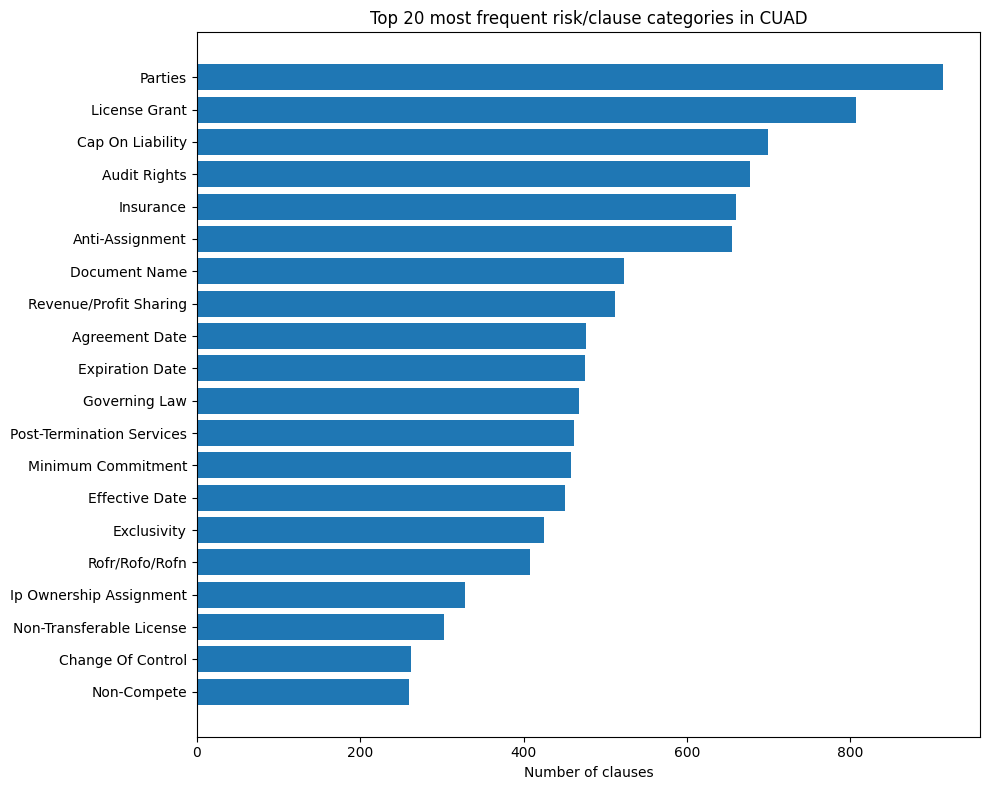

In [9]:
plt.figure(figsize=(10, 8))
top20 = label_df.head(20)
plt.barh(top20['category'], top20['count'])
plt.xlabel('Number of clauses')
plt.title('Top 20 most frequent risk/clause categories in CUAD')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

count    116497.00000
mean         34.43644
std          45.70212
min           1.00000
25%           8.00000
50%          25.00000
75%          44.00000
max        2730.00000
Name: clause_length_words, dtype: float64

Positive (has >=1 risk label): 10146
Negative (no risk label):      106351
Class imbalance ratio: 1 : 10.5


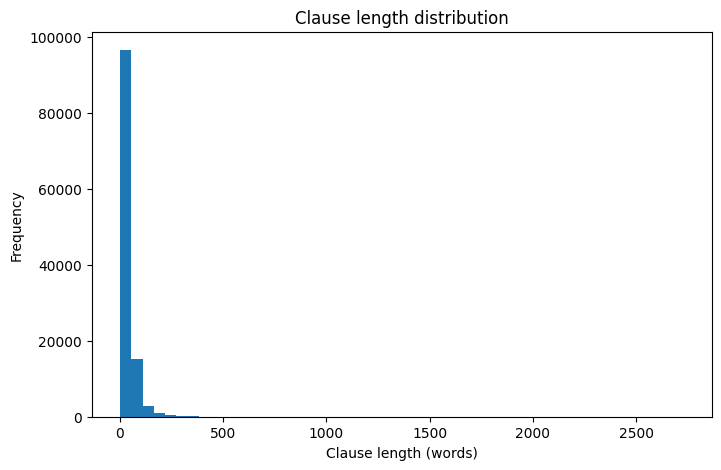

In [10]:
clause_df['clause_length_words'] = clause_df['clause_text'].apply(lambda x: len(x.split()))
clause_df['has_label'] = clause_df['labels'].apply(lambda x: len(x) > 0)

print(clause_df['clause_length_words'].describe())
print()
print("Positive (has >=1 risk label):", clause_df['has_label'].sum())
print("Negative (no risk label):     ", (~clause_df['has_label']).sum())
print(f"Class imbalance ratio: 1 : {(~clause_df['has_label']).sum() / max(clause_df['has_label'].sum(),1):.1f}")

plt.figure(figsize=(8,5))
plt.hist(clause_df['clause_length_words'], bins=50)
plt.xlabel('Clause length (words)')
plt.ylabel('Frequency')
plt.title('Clause length distribution')
plt.show()

# Part 2: Structure and rule-based flagging
`legal_nlp_utils.py`: PDF text, legal sentence splitter, sections, 29 rule categories.

In [11]:
%%writefile {PROJECT_DIR}/legal_nlp_utils.py
"""
legal_nlp_utils.py
Shared Stage-1 (classical NLP) utilities for the Legal Document Summariser project.
Written by Part 2 of Legal_Summariser_All_Days.ipynb and imported by the later parts.
"""

import json
import re

import pandas as pd
from tqdm.auto import tqdm

# ---------------- PDF ingestion ----------------

def extract_pdf_text(pdf_path):
    """PDF text with line breaks kept; pdfplumber, then PyMuPDF."""
    text = ''
    try:
        import pdfplumber
        with pdfplumber.open(pdf_path) as pdf:
            text = '\n'.join(p.extract_text() or '' for p in pdf.pages)
    except Exception as e:
        print('pdfplumber failed:', e)
    if len(text.strip()) < 50:
        try:
            try:
                import pymupdf as fitz
            except ImportError:
                import fitz
            doc = fitz.open(pdf_path)
            text = '\n'.join(page.get_text() for page in doc)
            doc.close()
        except Exception as e:
            print('PyMuPDF failed:', e)
    if len(text.strip()) < 50:
        raise ValueError(f'Could not extract text from {pdf_path} (scanned PDF? it would need OCR first).')
    return text


# ---------------- Legal-aware sentence splitting ----------------

LEGAL_ABBREVIATIONS = [
    "Sec.", "Art.", "No.", "Inc.", "Ltd.", "Co.", "Corp.", "vs.", "viz.",
    "etc.", "i.e.", "e.g.", "U.S.", "U.S.C.", "Mr.", "Mrs.", "Ms.", "Dr.",
    "Fig.", "cf.", "Para.", "Cl.", "Esq.", "Jr.", "Sr.", "al.", "Ave.",
]

# Abbreviations only match at the start of a word (so "renewal." isn't read as "al.")
_ABBR_RE = re.compile(r"(?<![A-Za-z])(" + "|".join(
    re.escape(a) for a in sorted(LEGAL_ABBREVIATIONS, key=len, reverse=True)) + ")")

def _protect_periods(text):
    protected = _ABBR_RE.sub(lambda m: m.group(0).replace(".", "\u0000"), text)
    protected = re.sub(r"(?<=\d)\.(?=\d)", "\u0001", protected)
    return protected

def _restore_periods(text):
    return text.replace("\u0000", ".").replace("\u0001", ".")

SENTENCE_SPLIT_RE = re.compile(r'(?<=[.!?])\s+(?=[A-Z"\u201c(\d])')

def split_into_legal_sentences(text):
    """Abbreviation- and numbering-aware sentence split."""
    protected = _protect_periods(text)
    pieces = SENTENCE_SPLIT_RE.split(protected)
    return [_restore_periods(p).strip() for p in pieces if p.strip()]

# ---------------- Document structure detection ----------------

def clean_extracted_text_light(text):
    """Removes page numbers and extra blank lines; keeps single line breaks."""
    text = re.sub(r"Page \d+ of \d+", "", text, flags=re.I)
    text = re.sub(r"[ \t]{2,}", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

HEADING_PATTERNS = [
    re.compile(r"^\s*(ARTICLE|SECTION)\s+[IVXLCDM\d]+[\.:]?\s*(.*)$", re.IGNORECASE),
    re.compile(r"^\s*\d+(\.\d+)*\s+[A-Z][A-Za-z0-9 ,\-/&']{3,80}$"),
    re.compile(r"^\s*[A-Z][A-Z0-9 ,\-/&']{6,80}$"),
    re.compile(r"^\s*\d+(\.\d+)*\.\s+[A-Z][A-Za-z0-9 ,\-/&']{2,80}$"),
]

# A line ending in one of these words is a wrapped clause line, not a heading
_CONNECTOR_END = re.compile(r"\b(A|AN|AND|ANY|AS|AT|BE|BY|FOR|FROM|IN|IS|ITS|OF|ON|OR|SUCH|THAT|THE|TO|WITH)$", re.IGNORECASE)
_SENTENCE_END = re.compile(r"[.:;!?)\]\"\u201d]$")

def is_heading(line):
    line = line.strip()
    if not line or len(line) > 100:
        return False
    return any(pat.match(line) for pat in HEADING_PATTERNS)

def _looks_like_heading(line, prev_line, prev_was_heading):
    """is_heading plus context: a heading must start a new block."""
    if not is_heading(line):
        return False
    prev = prev_line.strip()
    if prev and not prev_was_heading and not _SENTENCE_END.search(prev):
        return False
    text = line.strip()
    if _CONNECTOR_END.search(text):  # "4.2 Late payments accrue interest at the rate of" is a wrapped clause
        return False
    if text.isupper() and len(text.split()) > 12 and not re.match(r"^\s*((ARTICLE|SECTION)\s|\d)", text, re.I):
        return False
    return True

def split_into_sections(raw_text):
    """Splits line-break-preserved text into {heading, text} sections."""
    lines = raw_text.split("\n")
    sections = []
    current_heading = "Preamble"
    current_lines = []
    prev_line, prev_was_heading = "", True
    for line in lines:
        if _looks_like_heading(line, prev_line, prev_was_heading):
            if current_lines:
                sections.append({"heading": current_heading, "text": "\n".join(current_lines).strip()})
            current_heading = line.strip()
            current_lines = []
            prev_was_heading = True
        else:
            current_lines.append(line)
            prev_was_heading = False if line.strip() else prev_was_heading
        if line.strip():
            prev_line = line
    if current_lines:
        sections.append({"heading": current_heading, "text": "\n".join(current_lines).strip()})
    return [s for s in sections if s["text"]]

# ---------------- Rule-based risk flagging ----------------

# Developed on CUAD train contracts, checked on validation
RISK_PATTERNS = {
    'Termination for Convenience': [
        r'terminate\s+this\s+agreement.{0,40}(sole discretion|for convenience|without cause|for any reason)',
        r'may terminate.{0,30}at any time.{0,30}without cause',
        r'terminat\w*.{0,60}(with or without cause|without cause|for convenience|for any reason or no reason|for any or no reason)',
        r'may terminate this agreement.{0,40}at any time',
        r'until terminated by either party',
        r'(either|each) party may terminate this agreement.{0,40}(upon|by giving|on|with).{0,40}notice',
    ],
    'Automatic Renewal': [
        r'automatically (be )?(renew|extend)', r'(renew|extend)(ed|s)? automatically', r'auto-?renew',
        r'shall (automatically )?renew.{0,20}unless', r'successive (renewal )?(terms?|periods?)',
        r'(additional|successive|further) (\w+ )?(\(\d+\) )?(-?year|-?month|year|month)s? (renewal )?(terms?|periods?)',
        r'(option|right) to (renew|extend)', r'renewal (term|period)', r'month[- ]to[- ]month', r'year[- ]to[- ]year',
    ],
    'Notice Period to Avoid Renewal': [
        r'(notice|notify|notification|notifies).{0,80}(non-?renewal|not to renew|intent\w* not to (renew|extend)|not to extend)',
        r'unless.{0,100}notice.{0,100}(prior to|before|in advance of).{0,40}(end|expir\w*) of the (then[- ]current|initial|renewal|current)',
        r'(notice|notif\w*).{0,80}(no later than|at least|not less than|prior to|before).{0,60}(end|expir\w*) of (the|any|such) (then[- ]current |then in effect |initial |renewal |relevant |current )?(term|period)',
        r'until terminated by either party.{0,40}notice',
        r'unless.{0,60}party.{0,60}notice.{0,60}(intent|intention|election) (to terminate|not to)',
    ],
    'Indemnification': [
        r'indemnif', r'hold\s+harmless', r'defend.{0,20}indemnify',
    ],
    'Limitation of Liability': [
        r'limitation of liability', r'in no event (shall|will).{0,100}(liable|liability)',
        r'shall not exceed.{0,30}(fees|amount)',
        r'(liability|liable).{0,120}(shall not exceed|will not exceed|not to exceed|limited to|in excess of|greater than)',
        r'(neither party|no party).{0,60}liable.{0,80}(indirect|consequential|incidental|special|punitive)',
    ],
    'Uncapped or Unlimited Liability': [
        r'no limitation on liability', r'unlimited liability', r'without limitation.{0,20}liability',
        r'(limitations?|exclusions?|caps?) (of|on) liability.{0,60}(shall|will) not apply',
        r'(foregoing|above|preceding|these) (limitations?|exclusions?).{0,40}(shall|will|do) not apply',
        r'(shall|will) not (apply|limit).{0,80}(indemnif|gross negligence|willful misconduct|fraud|breach of (section|article|confidential))',
        r'except (for|with respect to|in connection with|as provided|to the extent).{0,250}(in no event|shall not be liable|will not be liable|(neither|no) party (shall|will) be liable)',
        r'^\W*(\w+ ){0,3}(except|excluding|other than)\b.{0,400}(liab|damages)',
        r'nothing (in|herein).{0,80}(limit|exclude|restrict).{0,40}liabilit',
        r'liab\w*.{0,200}\((except|excluding|other than)',
    ],
    'Non-Compete': [
        r'non[- ]?compet', r'shall not,? (directly or indirectly,? )?compete',
        r'restrict\w* .{0,30}competing business',
        r'competing (products?|business(es)?|services?|technolog)', r'compet(itive|ing) with',
        r'(not|neither).{0,80}(engage|participate|invest|represent|develop|manufacture|sell|market|distribute|promote|commercializ)\w*.{0,80}(compet|similar)',
    ],
    'Exclusivity': [
        r'exclusive(ly)? (right|license|arrangement|basis|distribut|supplier|provider|dealing|sales)', r'sole and exclusive',
        r'(exclusively|solely) (from|to|through|with)', r'(not|neither).{0,60}(purchase|buy|obtain|source).{0,40}from any (other|third)',
    ],
    'Arbitration or Jury Waiver': [
        r'binding arbitration', r'waives?.{0,20}right to (a )?(trial by )?jury', r'arbitration association',
        r'trial by jury', r'class action',
    ],
    'Assignment Restriction': [
        r'shall not assign', r'without (the )?prior written consent.{0,30}assign',
        r'(may|shall|will|can) not (\w+ ){0,4}(assign|transfer)', r'not (be )?(assignable|transferable)',
        r'assign\w*.{0,100}without.{0,30}(prior )?(express )?(written )?consent',
        r'(no|neither) party (may|shall|will).{0,30}assign',
    ],
    'Change of Control': [
        r'change (of|in) (control|ownership)', r'change of management',
        r'(merger|consolidation|acquisition|reorganization).{0,100}(assign|terminat|consent|transfer)',
        r'(sale|transfer) of (all or )?substantially all', r'(liquidity|liquidation) event',
        r'(sale|transfer|acquisition) of.{0,40}(voting|controlling|equity) (stock|interests?|shares|securities)',
    ],
    'Confidentiality': [
        r'confidential information', r'non-disclosure',
    ],
    'Unilateral Modification': [
        r'sole discretion.{0,30}(modify|amend|change)', r'reserves the right to (change|modify|amend)',
        r'may (change|modify|amend|update) (these|this|the) (terms|agreement).{0,40}(at any time|from time to time|without)',
    ],
    'Waiver of Rights': [
        r'waives?.{0,20}(any )?(right|claim)', r'irrevocably waives?',
    ],
    'Covenant Not to Sue': [
        r'covenants? not to (sue|assert|bring)',
        r'(not|never)[\w ,]{0,60}(contest|challenge|attack|dispute|oppose)\w*.{0,80}(validity|ownership|title|rights|enforceability)',
        r'(not|never)[\w ,]{0,40}(commence|bring|institute|assert|file)\w*.{0,60}(suit|action|claim|proceeding)',
        r'(not|never)[\w ,()]{0,80}(oppose|challenge|contest|attack)\b',
        r'(not|never).{0,80}(impair|jeopardi[sz]e).{0,40}(rights?|title|ownership|marks?)',
        r'releases?( and discharges?)?.{0,60}(from )?(all|any) (and all )?claims', r'general release',
    ],
    'No-Solicit of Employees': [
        r'non-?solicit',
        r'solicit\w*.{0,80}(employ|personnel|staff|consultants?|contractors?)',
        r'(hire|employ|engage|recruit)\w*.{0,50}(employees?|personnel|staff) of',
        r'(induce|entice|encourage)\w*.{0,60}(employee|personnel|staff).{0,60}(leave|terminat)',
    ],
    'No-Solicit of Customers': [
        r'solicit\w*.{0,80}(customers?|clients?|suppliers?|vendors?|accounts?|business)',
        r'divert\w*.{0,60}(business|customers?|clients?)', r'circumvent',
        r'interfer\w*.{0,60}relationships?.{0,60}(customers?|clients?|suppliers?)',
    ],
    'Non-Disparagement': [
        r'disparag', r'defam', r'(negative|derogatory|critical).{0,30}(comments?|statements?|remarks?)',
        r'(harm|damage|injur|impair|jeopardi)\w*.{0,40}(reputation|goodwill|image)', r'publicly criticiz',
    ],
    'Audit Rights': [
        r'right to audit', r'audit.{0,30}(records|books)', r'\baudit', r'(inspect|examin)\w*.{0,60}(books|records|accounts)',
    ],
    'IP Ownership Transfer': [
        r'shall own all right, title', r'work[- ]made[- ]for[- ]hire',
        r'assigns? all right, title and interest',
        r'(hereby )?assign\w*.{0,60}(right,? title,? and interest|intellectual property)',
        r'(shall|will) (vest|belong) (solely |exclusively )?(in|to)',
        r'(intellectual property|inventions?|work product|deliverables|improvements).{0,80}(shall|will) (be|become|remain) the (sole and exclusive |exclusive |sole )?property',
    ],
    'Joint IP Ownership': [
        r'joint(ly)?[- ]own', r'joint (intellectual property|inventions?|ip|patents?|technology)', r'undivided interest', r'co-?own',
    ],
    'Irrevocable or Perpetual License': [
        r'(perpetual|irrevocable)[\w ,\-()]{0,80}licen[cs]e', r'licen[cs]e[\w ,\-()]{0,60}(perpetual|irrevocable)',
    ],
    'Source Code Escrow': [
        r'escrow', r'source code',
    ],
    'Insurance Requirement': [
        r'maintain insurance', r'certificate of insurance', r'insurance', r'\binsured\b',
    ],
    'Liquidated Damages': [
        r'liquidated damages', r'termination (fee|charge|payment)', r'break-?up fee', r'early termination (fee|charge|payment)',
        r'(as|constitute)( a)? (penalty|forfeiture)',
    ],
    'Most Favored Nation': [
        r'most favou?red (nation|customer|pricing|licensee)', r'(no|not) less favou?rabl[ey]',
        r'more favou?rable (terms|prices?|pricing|conditions|rates?)', r'(lowest|best) (net )?prices?',
        r'(not|never) (be )?charged? (a )?higher',
    ],
    'Price Restrictions': [
        r'(increase|raise|adjust)\w*.{0,60}(prices?|fees?|rates?).{0,80}(no more than|not more than|not to exceed|shall not exceed|once (per|in|each|a)|annually|cpi)',
        r'(prices?|fees?|rates?).{0,40}(shall|will|may) not (be )?(increased?|exceed|changed?)',
        r'consumer price index', r'\bCPI\b',
    ],
    'Cap on Liability': [
        r'aggregate liability.{0,40}shall not exceed',
    ],
    'Third Party Beneficiary': [
        r'third[- ]party beneficiar', r'intended beneficiar',
    ],
}

# Rule category -> CUAD category (unmapped rules keep their own name)
RULE_TO_CUAD = {
    'Termination for Convenience': 'Termination For Convenience',
    'Automatic Renewal': 'Renewal Term',
    'Notice Period to Avoid Renewal': 'Notice Period To Terminate Renewal',
    'Limitation of Liability': 'Cap On Liability',
    'Cap on Liability': 'Cap On Liability',
    'Uncapped or Unlimited Liability': 'Uncapped Liability',
    'Non-Compete': 'Non-Compete',
    'Exclusivity': 'Exclusivity',
    'Assignment Restriction': 'Anti-Assignment',
    'Change of Control': 'Change Of Control',
    'Covenant Not to Sue': 'Covenant Not To Sue',
    'No-Solicit of Employees': 'No-Solicit Of Employees',
    'No-Solicit of Customers': 'No-Solicit Of Customers',
    'Non-Disparagement': 'Non-Disparagement',
    'Audit Rights': 'Audit Rights',
    'IP Ownership Transfer': 'Ip Ownership Assignment',
    'Joint IP Ownership': 'Joint Ip Ownership',
    'Irrevocable or Perpetual License': 'Irrevocable Or Perpetual License',
    'Source Code Escrow': 'Source Code Escrow',
    'Insurance Requirement': 'Insurance',
    'Liquidated Damages': 'Liquidated Damages',
    'Most Favored Nation': 'Most Favored Nation',
    'Price Restrictions': 'Price Restrictions',
    'Third Party Beneficiary': 'Third Party Beneficiary',
}

COMPILED_RISK_PATTERNS = {cat: [re.compile(p, re.IGNORECASE) for p in pats] for cat, pats in RISK_PATTERNS.items()}

def flag_clause(clause_text):
    """Returns the list of rule categories whose patterns match this clause."""
    matches = []
    for category, patterns in COMPILED_RISK_PATTERNS.items():
        if any(pat.search(clause_text) for pat in patterns):
            matches.append(category)
    return matches

def to_cuad_names(rule_flags):
    """Maps rule category names to CUAD names (unmapped rule categories keep their name), without duplicates."""
    out = []
    for r in rule_flags:
        c = RULE_TO_CUAD.get(r, r)
        if c not in out:
            out.append(c)
    return out

# ---------------- Combined Stage-1 pipeline ----------------

def process_document(raw_text):
    """Full Stage-1 pipeline: detect sections, split into clauses, apply rule-based flags."""
    light_cleaned = clean_extracted_text_light(raw_text)
    sections = split_into_sections(light_cleaned)
    rows = []
    for sec in sections:
        clauses = split_into_legal_sentences(sec['text'])
        for clause in clauses:
            # Join PDF line wraps so patterns can match across them
            clause = re.sub(r"\s*\n\s*", " ", clause)
            if len(clause.split()) < 4:
                continue  # skip near-empty fragments (stray headers, page artifacts)
            rows.append({
                'section': sec['heading'],
                'clause_text': clause,
                'rule_flags': flag_clause(clause),
            })
    return pd.DataFrame(rows)

# ---------------- CUAD clause table (training and evaluation) ----------------

def build_clause_df(json_path):
    """One row per clause, labelled with the CUAD categories whose answer span overlaps it."""
    with open(json_path) as f:
        cuad_raw = json.load(f)
    rows = []
    for entry in tqdm(cuad_raw['data'], desc='building clause table'):
        for para in entry['paragraphs']:
            context = para['context']
            spans = []  # (category, start, end)
            for qa in para['qas']:
                m = re.search(r'"([^"]+)"', qa['question'])
                cat = m.group(1) if m else qa['question'][:40]
                for a in qa.get('answers', []):
                    if a.get('text', '').strip():
                        spans.append((cat, a['answer_start'], a['answer_start'] + len(a['text'])))
            cursor = 0
            for clause in split_into_legal_sentences(context):
                start = context.find(clause, cursor)
                if start == -1:  # should not happen; fall back to a substring search from the beginning
                    start = context.find(clause)
                end = start + len(clause)
                if start != -1:
                    cursor = end
                labels = {cat for cat, s, e in spans if start != -1 and s < end and e > start}
                rows.append({'contract_id': entry['title'], 'clause_text': clause, 'labels': sorted(labels)})
    return pd.DataFrame(rows)

Overwriting /Users/neeharikapai/small_projects/nlpproject/legal_doc_summariser/legal_nlp_utils.py


In [12]:
from legal_nlp_utils import (extract_pdf_text, clean_extracted_text_light, split_into_legal_sentences, split_into_sections,
                             flag_clause, to_cuad_names, process_document, build_clause_df, RISK_PATTERNS, RULE_TO_CUAD)

## 2.1 PDF ingestion

In [13]:
sample_files = sorted(f for f in os.listdir(SAMPLE_DIR) if f.lower().endswith('.pdf'))
print("Sample contracts available:", sample_files)
if sample_files:
    raw_text = extract_pdf_text(os.path.join(SAMPLE_DIR, sample_files[0]))
    print(f"Extracted {len(raw_text)} characters from {sample_files[0]}. First 800 chars:\n")
    print(raw_text[:800])
else:
    print("No PDFs found yet -- add a contract PDF to:", SAMPLE_DIR)

Sample contracts available: ['synthetic_mutual_nda.pdf', 'synthetic_residential_lease.pdf', 'synthetic_saas_terms.pdf']
Extracted 3150 characters from synthetic_mutual_nda.pdf. First 800 chars:

MUTUAL NON-DISCLOSURE AGREEMENT
This Mutual Non-Disclosure Agreement (the "Agreement") is entered into as of March 3, 2025
(the "Effective Date") by and between Northwind Analytics Ltd., a company incorporated in
England ("Northwind"), and Harbor Robotics Inc., a Delaware corporation ("Harbor").
The parties wish to explore a possible collaboration on warehouse analytics (the "Purpose") and
to protect the information they exchange for that Purpose.
1. DEFINITIONS
"Confidential Information" means any non-public business, technical or financial information
disclosed by either party, whether in writing, orally or by inspection, that is marked as
confidential or would reasonably be understood to be confidential.
2. OBLIGATIONS OF THE RECEIVING PARTY
The Receiving Party shall hold all Confidenti


## 2.2 Legal-aware sentence splitter

In [14]:
# Default spaCy split vs legal-aware split
test_snippet = (
    "Pursuant to Sec. 3.2.1 of this Agreement, the Vendor (\"Inc.\") shall deliver the goods "
    "by no later than 30 days. Notwithstanding the foregoing, Art. 5 governs disputes. "
    "The parties agree that termination under clause 4.1.2 requires written notice."
)

nlp_default = spacy.load("en_core_web_sm")
print("=== Default spaCy sentence split ===")
for s in nlp_default(test_snippet).sents:
    print("-", s.text.strip())

print()
print("=== Legal-aware split ===")
for s in split_into_legal_sentences(test_snippet):
    print("-", s)

=== Default spaCy sentence split ===
- Pursuant to Sec.
- 3.2.1 of this Agreement, the Vendor ("Inc.") shall deliver the goods by no later than 30 days.
- Notwithstanding the foregoing, Art.
- 5 governs disputes.
- The parties agree that termination under clause 4.1.2 requires written notice.

=== Legal-aware split ===
- Pursuant to Sec. 3.2.1 of this Agreement, the Vendor ("Inc.") shall deliver the goods by no later than 30 days.
- Notwithstanding the foregoing, Art. 5 governs disputes.
- The parties agree that termination under clause 4.1.2 requires written notice.


## 2.3 Section detection

In [15]:
if sample_files:
    sections = split_into_sections(clean_extracted_text_light(raw_text))
    print(f"Detected {len(sections)} sections.\n")
    for sec in sections[:8]:
        print(f"### {sec['heading']}")
        print(sec['text'][:150].replace(chr(10), ' '), "...\n")

Detected 9 sections.

### MUTUAL NON-DISCLOSURE AGREEMENT
This Mutual Non-Disclosure Agreement (the "Agreement") is entered into as of March 3, 2025 (the "Effective Date") by and between Northwind Analytics L ...

### 1. DEFINITIONS
"Confidential Information" means any non-public business, technical or financial information disclosed by either party, whether in writing, orally or  ...

### 2. OBLIGATIONS OF THE RECEIVING PARTY
The Receiving Party shall hold all Confidential Information in strict confidence and shall not disclose it to any third party for a period of five (5) ...

### 3. NON-SOLICITATION
During the term of this Agreement and for twelve (12) months thereafter, neither party shall, directly or indirectly, solicit for employment or hire a ...

### 4. RESTRICTED ACTIVITIES
For a period of two (2) years after the Effective Date, Harbor shall not engage in, or assist any third party in, the development of any analytics pla ...

### 5. REMEDIES
Each party acknowledges that a b

## 2.4 Rule-based flags

In [16]:
# Rule flags on test sentences
test_clauses = [
    "The Company may terminate this Agreement at any time, for any reason, in its sole discretion.",
    "This Agreement shall automatically renew for successive one-year terms unless either party provides notice.",
    "Vendor shall indemnify and hold harmless Client from any claims arising out of Vendor's breach.",
    "The weather in the region has historically been mild throughout the year.",  # negative control
]

for c in test_clauses:
    print(f"Clause: {c}")
    print(f"Flags:  {flag_clause(c)}\n")

Clause: The Company may terminate this Agreement at any time, for any reason, in its sole discretion.
Flags:  ['Termination for Convenience']

Clause: This Agreement shall automatically renew for successive one-year terms unless either party provides notice.
Flags:  ['Automatic Renewal']

Clause: Vendor shall indemnify and hold harmless Client from any claims arising out of Vendor's breach.
Flags:  ['Indemnification']

Clause: The weather in the region has historically been mild throughout the year.
Flags:  []



## 2.5 Rule recall on CUAD

In [17]:
rule_cats = clause_df['clause_text'].apply(lambda t: set(to_cuad_names(flag_clause(t))))
rows = []
for cuad_cat in sorted(set(RULE_TO_CUAD.values())):
    gold = clause_df['labels'].apply(lambda labels: cuad_cat in labels)
    hit = rule_cats.apply(lambda cats: cuad_cat in cats)
    rows.append({'CUAD category': cuad_cat, 'gold clauses': int(gold.sum()), 'rule hits': int(hit.sum()),
                 'recall': (gold & hit).sum() / max(gold.sum(), 1), 'precision': (gold & hit).sum() / max(hit.sum(), 1)})
rule_check = pd.DataFrame(rows).sort_values('recall')
print(f"Mean recall over {len(rule_check)} mapped categories: {rule_check['recall'].mean():.3f}")
display(rule_check.round(3))

Mean recall over 23 mapped categories: 0.537


,CUAD category,gold clauses,rule hits,recall,precision
14,Non-Compete,260,277,0.292,0.274
7,Ip Ownership Assignment,328,239,0.299,0.410
17,Price Restrictions,26,63,0.308,0.127
5,Exclusivity,425,1016,0.344,0.144
4,Covenant Not To Sue,165,276,0.364,0.217
2,Cap On Liability,699,537,0.383,0.499
20,Termination For Convenience,237,238,0.384,0.382
11,Most Favored Nation,37,39,0.405,0.385
12,No-Solicit Of Customers,55,95,0.473,0.274
16,Notice Period To Terminate Renewal,126,112,0.540,0.607


# Part 3: Legal-BERT clause classifier
`TRAIN_MODEL = False` loads the model trained on the college GPU (20 categories); `True` retrains (GPU only).

In [18]:
TRAIN_MODEL = False   # True = retrain (GPU only; overwrites the saved model)

if TRAIN_MODEL:
    if DEVICE.type == 'cpu':
        raise RuntimeError(
            "No GPU found. On Colab: Runtime -> Change runtime type -> T4 GPU, then re-run from the top. "
            "On a Mac: make sure you installed a recent torch (pip install -U torch) so MPS is available.")
    USE_AMP = DEVICE.type == 'cuda'   # fp16 mixed precision only on CUDA; MPS runs in fp32
    print(f"Training on {DEVICE}")
else:
    assert os.path.exists(os.path.join(CLF_DIR, 'clf_meta.json')), (
        "Trained model not found in models/legal_bert_clause_clf/ -- unzip legal_bert_trained.zip inside legal_doc_summariser/.")
    print("TRAIN_MODEL is False: using the trained model in", CLF_DIR)

TRAIN_MODEL is False: using the trained model in /Users/neeharikapai/small_projects/nlpproject/legal_doc_summariser/models/legal_bert_clause_clf


## 3.1 Clause table (training only)

In [19]:
CLAUSE_PKL = os.path.join(DATA_DIR, 'cuad_clause_level_v2.pkl')
if TRAIN_MODEL:
    if os.path.exists(CLAUSE_PKL):
        train_clause_df = pd.read_pickle(CLAUSE_PKL)
    else:
        train_clause_df = build_clause_df(CUAD_JSON)
        train_clause_df.to_pickle(CLAUSE_PKL)
    train_clause_df = train_clause_df[train_clause_df['clause_text'].str.split().str.len() >= 4].reset_index(drop=True)
    print(f"{len(train_clause_df):,} clauses from {train_clause_df['contract_id'].nunique()} contracts")
    print(f"Clauses with >=1 label: {(train_clause_df['labels'].str.len() > 0).sum():,}")

## 3.2 Labels and contract-level split (70/15/15)

In [20]:
if TRAIN_MODEL:
    N_CATEGORIES = 41   # all CUAD categories (risk categories like Renewal Term and Uncapped Liability are rare, but must be learned)
    label_counts = Counter(l for labels in train_clause_df['labels'] for l in labels)
    CATEGORIES = [c for c, _ in label_counts.most_common(N_CATEGORIES)]
    CAT2IDX = {c: i for i, c in enumerate(CATEGORIES)}
    print(pd.DataFrame(label_counts.most_common(N_CATEGORIES), columns=['category', 'clauses']).to_string(index=False))


    def to_multi_hot(labels):
        v = np.zeros(len(CATEGORIES), dtype=np.float32)
        for l in labels:
            if l in CAT2IDX:
                v[CAT2IDX[l]] = 1.0
        return v


    contract_ids = np.array(sorted(train_clause_df['contract_id'].unique()))
    rng = np.random.default_rng(SEED)
    rng.shuffle(contract_ids)
    n = len(contract_ids)
    n_train, n_val = int(0.70 * n), int(0.15 * n)
    split_ids = {
        'train': contract_ids[:n_train].tolist(),
        'val': contract_ids[n_train:n_train + n_val].tolist(),
        'test': contract_ids[n_train + n_val:].tolist(),
    }
    with open(os.path.join(DATA_DIR, 'split_contract_ids.json'), 'w') as f:
        json.dump(split_ids, f)

    splits = {k: train_clause_df[train_clause_df['contract_id'].isin(v)].reset_index(drop=True) for k, v in split_ids.items()}
    for k, df in splits.items():
        pos = (df['labels'].apply(lambda ls: any(l in CAT2IDX for l in ls))).sum()
        print(f"{k:5s}: {len(split_ids[k]):3d} contracts, {len(df):6,d} clauses, {pos:5,d} with a label")

## 3.3 Class imbalance: negative down-sampling + pos_weight

In [21]:
if TRAIN_MODEL:
    NEG_RATIO = 2.0

    train_df = splits['train']
    is_pos = train_df['labels'].apply(lambda ls: any(l in CAT2IDX for l in ls))
    pos_df, neg_df = train_df[is_pos], train_df[~is_pos]
    neg_keep = neg_df.sample(n=min(len(neg_df), int(NEG_RATIO * len(pos_df))), random_state=SEED)
    train_bal = pd.concat([pos_df, neg_keep]).sample(frac=1, random_state=SEED).reset_index(drop=True)

    Y_train = np.stack(train_bal['labels'].apply(to_multi_hot).values)
    pos_counts = Y_train.sum(axis=0)
    pos_weight = torch.tensor(np.clip((len(Y_train) - pos_counts) / np.maximum(pos_counts, 1), 1.0, 10.0), dtype=torch.float32)

    print(f"Training clauses after down-sampling: {len(train_bal):,} ({len(pos_df):,} labelled + {len(neg_keep):,} unlabelled)")
    print(pd.DataFrame({'category': CATEGORIES, 'train_positives': pos_counts.astype(int),
                        'pos_weight': pos_weight.numpy().round(2)}).to_string(index=False))

## 3.4 Tokenise

In [22]:
if TRAIN_MODEL:
    BASE_MODEL = 'nlpaueb/legal-bert-base-uncased'
    MAX_LEN = 256
    BATCH_SIZE = 32 if DEVICE.type == 'cuda' else 16

    tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

    sample_lens = [len(tokenizer.encode(t)) for t in train_bal['clause_text'].sample(min(2000, len(train_bal)), random_state=SEED)]
    print("Token length percentiles (50/90/95/99):", np.percentile(sample_lens, [50, 90, 95, 99]).round())
    print(f"Share of clauses that fit in MAX_LEN={MAX_LEN}: {np.mean(np.array(sample_lens) <= MAX_LEN):.1%}")

In [23]:
if TRAIN_MODEL:
    from torch.utils.data import Dataset, DataLoader


    class ClauseDataset(Dataset):
        def __init__(self, df):
            self.texts = df['clause_text'].tolist()
            self.labels = np.stack(df['labels'].apply(to_multi_hot).values) if len(df) else np.zeros((0, len(CATEGORIES)))

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, i):
            return self.texts[i], self.labels[i]


    def collate(batch):
        texts, labels = zip(*batch)
        enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding=True, return_tensors='pt')
        enc['labels'] = torch.tensor(np.stack(labels), dtype=torch.float32)
        return enc


    train_loader = DataLoader(ClauseDataset(train_bal), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
    val_loader = DataLoader(ClauseDataset(splits['val']), batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collate)
    test_loader = DataLoader(ClauseDataset(splits['test']), batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collate)
    print(f"Batches per epoch: {len(train_loader)}")

## 3.5 Model and training loop

In [24]:
if TRAIN_MODEL:
    EPOCHS = 3
    LR = 2e-5
    WARMUP_FRAC = 0.1

    model = AutoModelForSequenceClassification.from_pretrained(
        BASE_MODEL, num_labels=len(CATEGORIES), problem_type='multi_label_classification',
        id2label=dict(enumerate(CATEGORIES)), label2id=CAT2IDX,
    ).to(DEVICE)
    print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")

    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total_steps = EPOCHS * len(train_loader)
    warmup_steps = int(WARMUP_FRAC * total_steps)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: s / max(1, warmup_steps) if s < warmup_steps else max(0.0, (total_steps - s) / max(1, total_steps - warmup_steps)))
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    from contextlib import nullcontext
    amp_ctx = (lambda: torch.autocast(device_type='cuda', dtype=torch.float16)) if USE_AMP else nullcontext


    @torch.no_grad()
    def predict_probs(loader):
        model.eval()
        all_probs, all_labels = [], []
        for batch in tqdm(loader, desc='predict', leave=False):
            labels = batch.pop('labels')
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with amp_ctx():
                logits = model(**batch).logits
            all_probs.append(torch.sigmoid(logits.float()).cpu().numpy())
            all_labels.append(labels.numpy())
        return np.concatenate(all_probs), np.concatenate(all_labels)


    def macro_scores(y_true, y_pred, beta=2.0):
        p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)
        fb = (1 + beta**2) * p * r / np.maximum(beta**2 * p + r, 1e-9)
        return {'precision': p.mean(), 'recall': r.mean(), 'f1': f1.mean(), 'f2': fb.mean()}

In [25]:
if TRAIN_MODEL:
    history, best_f2 = [], -1.0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running, t0 = 0.0, time.time()
        pbar = tqdm(train_loader, desc=f'epoch {epoch}/{EPOCHS}')
        for step, batch in enumerate(pbar, 1):
            labels = batch.pop('labels').to(DEVICE)
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with amp_ctx():
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
            if step % 20 == 0:
                pbar.set_postfix(loss=f"{running/step:.4f}")

        val_probs, val_true = predict_probs(val_loader)
        scores = macro_scores(val_true, (val_probs >= 0.5).astype(int))
        history.append({'epoch': epoch, 'train_loss': running / len(train_loader), **{f'val_{k}': v for k, v in scores.items()},
                        'minutes': (time.time() - t0) / 60})
        print(f"epoch {epoch}: train_loss={history[-1]['train_loss']:.4f}  val macro P/R/F1/F2 @0.5 = "
              f"{scores['precision']:.3f}/{scores['recall']:.3f}/{scores['f1']:.3f}/{scores['f2']:.3f}  ({history[-1]['minutes']:.1f} min)")

        if scores['f2'] > best_f2:
            best_f2 = scores['f2']
            model.save_pretrained(CLF_DIR)
            tokenizer.save_pretrained(CLF_DIR)
            print(f"  -> new best, saved to {CLF_DIR}")

    history_df = pd.DataFrame(history)
    history_df.to_csv(os.path.join(MODEL_DIR, 'training_history.csv'), index=False)
    display(history_df)

,epoch,train_loss,val_precision,val_recall,val_f1,val_f2,minutes
0,1,0.174546,0.501719,0.741831,0.584637,0.662779,8.752717
1,2,0.054062,0.495912,0.808231,0.601660,0.704025,8.535559
2,3,0.035729,0.555768,0.778249,0.637445,0.710330,8.693192


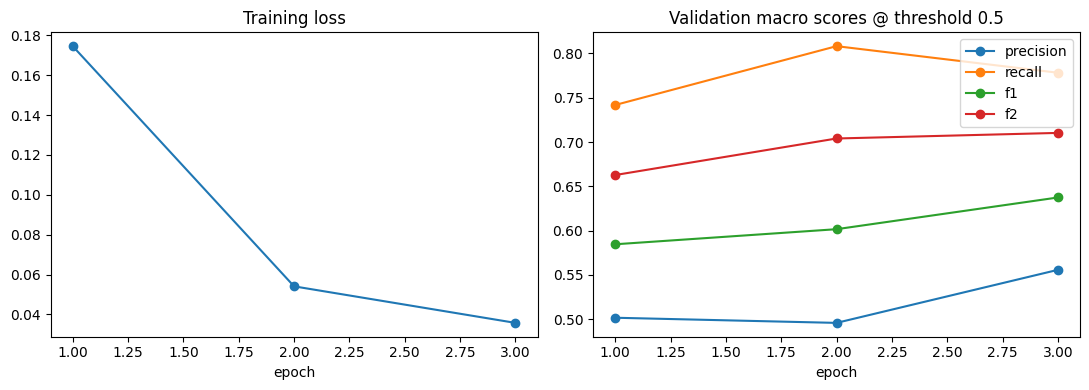

In [26]:
if not TRAIN_MODEL:
    history_df = pd.read_csv(os.path.join(MODEL_DIR, 'training_history.csv'))   # saved by the college GPU run
    display(history_df)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history_df['epoch'], history_df['train_loss'], marker='o'); ax[0].set_title('Training loss'); ax[0].set_xlabel('epoch')
for k in ['val_precision', 'val_recall', 'val_f1', 'val_f2']:
    ax[1].plot(history_df['epoch'], history_df[k], marker='o', label=k.replace('val_', ''))
ax[1].set_title('Validation macro scores @ threshold 0.5'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(MODEL_DIR, 'training_curves.png'), dpi=120); plt.show()

## 3.6 Per-category thresholds (F2, validation)

In [27]:
if TRAIN_MODEL:
    model = AutoModelForSequenceClassification.from_pretrained(CLF_DIR).to(DEVICE)   # reload best epoch
    val_probs, val_true = predict_probs(val_loader)

    rows = []
    for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
        s = macro_scores(val_true, (val_probs >= t).astype(int))
        rows.append({'threshold': t, **{k: round(v, 3) for k, v in s.items()}})
    print("Global threshold sweep (validation, macro-averaged):")
    print(pd.DataFrame(rows).to_string(index=False))

    GRID = np.round(np.arange(0.05, 0.51, 0.05), 2)
    thresholds = []
    for j in range(len(CATEGORIES)):
        best_t, best = 0.5, -1
        for t in GRID:
            pred = (val_probs[:, j] >= t).astype(int)
            p, r, _, _ = precision_recall_fscore_support(val_true[:, j], pred, average='binary', zero_division=0)
            f2 = 5 * p * r / max(4 * p + r, 1e-9)
            if f2 > best:
                best, best_t = f2, float(t)
        thresholds.append(best_t)
    THRESHOLDS = np.array(thresholds)
    print("\nPer-category thresholds:")
    print(pd.DataFrame({'category': CATEGORIES, 'threshold': THRESHOLDS}).to_string(index=False))

In [28]:
if not TRAIN_MODEL:
    with open(os.path.join(CLF_DIR, 'clf_meta.json')) as f:
        clf_meta = json.load(f)
    CATEGORIES, THRESHOLDS = clf_meta['categories'], np.array(clf_meta['thresholds'])
    print(f"Fine-tuned {clf_meta['base_model']}: {len(CATEGORIES)} categories, {clf_meta['epochs']} epochs, "
          f"best val macro F2 @0.5 = {clf_meta['best_val_macro_f2_at_0.5']:.3f}")
    print("\nPer-category thresholds (tuned on validation):")
    print(pd.DataFrame({'category': CATEGORIES, 'threshold': THRESHOLDS}).to_string(index=False))

Fine-tuned nlpaueb/legal-bert-base-uncased: 20 categories, 3 epochs, best val macro F2 @0.5 = 0.710

Per-category thresholds (tuned on validation):
                   category  threshold
                    Parties       0.05
              Document Name       0.50
             Agreement Date       0.15
              License Grant       0.45
            Anti-Assignment       0.50
             Effective Date       0.15
           Cap On Liability       0.20
               Audit Rights       0.50
                  Insurance       0.40
            Expiration Date       0.50
              Governing Law       0.30
  Post-Termination Services       0.45
                Exclusivity       0.50
         Minimum Commitment       0.35
     Revenue/Profit Sharing       0.35
             Rofr/Rofo/Rofn       0.50
    Ip Ownership Assignment       0.35
   Non-Transferable License       0.50
                Non-Compete       0.50
Termination For Convenience       0.30


## 3.7 Test-set evaluation

In [29]:
if TRAIN_MODEL:
    test_probs, test_true = predict_probs(test_loader)
    test_pred = (test_probs >= THRESHOLDS).astype(int)

    p, r, f1, support = precision_recall_fscore_support(test_true, test_pred, average=None, zero_division=0)
    dl_report = pd.DataFrame({'category': CATEGORIES, 'support': support.astype(int),
                              'precision': p.round(3), 'recall': r.round(3), 'f1': f1.round(3)}).sort_values('recall')
    print(dl_report.to_string(index=False))
    mp, mr, mf, _ = precision_recall_fscore_support(test_true, test_pred, average='micro', zero_division=0)
    print(f"\nMacro  P/R/F1: {p.mean():.3f} / {r.mean():.3f} / {f1.mean():.3f}")
    print(f"Micro  P/R/F1: {mp:.3f} / {mr:.3f} / {mf:.3f}")
    dl_report.to_csv(os.path.join(MODEL_DIR, 'test_report_legal_bert.csv'), index=False)
else:
    # Saved results from the college GPU run
    dl_report = pd.read_csv(os.path.join(MODEL_DIR, 'test_report_legal_bert.csv'))
    print(dl_report.to_string(index=False))
    print(f"\nMacro recall: {dl_report['recall'].mean():.3f}   macro precision: {dl_report['precision'].mean():.3f}")

                   category  threshold  support  precision  recall    f1
             Effective Date       0.15      215      0.304   0.447 0.362
              Document Name       0.50      258      0.629   0.519 0.569
  Post-Termination Services       0.45       58      0.278   0.638 0.387
             Rofr/Rofo/Rofn       0.50       42      0.397   0.643 0.491
   Non-Transferable License       0.50       70      0.522   0.671 0.588
                Exclusivity       0.50       54      0.342   0.722 0.464
     Revenue/Profit Sharing       0.35       65      0.467   0.754 0.576
              License Grant       0.45      125      0.608   0.768 0.678
           Cap On Liability       0.20      112      0.624   0.786 0.696
             Agreement Date       0.15      198      0.492   0.788 0.606
                Non-Compete       0.50       29      0.333   0.793 0.469
         Minimum Commitment       0.35       49      0.390   0.796 0.523
    Ip Ownership Assignment       0.35       36    

## 3.8 Rules vs Legal-BERT vs ensemble

In [30]:
if TRAIN_MODEL:
    train_test_df = splits['test'].copy()
    train_test_df['rule_flags'] = train_test_df['clause_text'].apply(flag_clause)

    rows = []
    for cuad_cat in sorted(set(RULE_TO_CUAD.values())):
        rule_names = [r for r, c in RULE_TO_CUAD.items() if c == cuad_cat]
        gold = train_test_df['labels'].apply(lambda ls: cuad_cat in ls).values
        if gold.sum() == 0:
            continue
        rule_hit = train_test_df['rule_flags'].apply(lambda fl: any(r in fl for r in rule_names)).values
        dl_hit = test_pred[:, CAT2IDX[cuad_cat]].astype(bool) if cuad_cat in CAT2IDX else np.zeros(len(train_test_df), bool)
        rows.append({
            'CUAD category': cuad_cat, 'in DL label set': cuad_cat in CAT2IDX, 'gold clauses': int(gold.sum()),
            'recall rules': (rule_hit & gold).sum() / gold.sum(),
            'recall Legal-BERT': (dl_hit & gold).sum() / gold.sum(),
            'recall ensemble': ((rule_hit | dl_hit) & gold).sum() / gold.sum(),
        })
    ensemble_df = pd.DataFrame(rows)
    print(ensemble_df.round(3).to_string(index=False))
    ensemble_df.to_csv(os.path.join(MODEL_DIR, 'test_ensemble_recall.csv'), index=False)
else:
    ensemble_df = pd.read_csv(os.path.join(MODEL_DIR, 'test_ensemble_recall.csv'))   # from the college GPU run
    print(ensemble_df.round(3).to_string(index=False))

              CUAD category  gold  recall rules  recall Legal-BERT  recall ensemble
            Anti-Assignment    98         0.031              0.878            0.878
               Audit Rights   117         0.120              0.855            0.855
           Cap On Liability   112         0.134              0.786            0.795
                Exclusivity    54         0.204              0.722            0.741
                  Insurance   104         0.144              0.894            0.894
    Ip Ownership Assignment    36         0.111              0.833            0.833
         Liquidated Damages     9         0.111              0.000            0.111
        Most Favored Nation     6         0.000              0.000            0.000
                Non-Compete    29         0.000              0.793            0.793
               Renewal Term    23         0.304              0.000            0.304
Termination For Convenience    35         0.114              0.943          

## 3.9 Save

In [31]:
if TRAIN_MODEL:
    meta = {
        'base_model': BASE_MODEL, 'categories': CATEGORIES, 'thresholds': THRESHOLDS.tolist(),
        'max_len': MAX_LEN, 'rule_to_cuad': RULE_TO_CUAD, 'epochs': EPOCHS, 'lr': LR, 'neg_ratio': NEG_RATIO,
        'best_val_macro_f2_at_0.5': best_f2,
    }
    with open(os.path.join(CLF_DIR, 'clf_meta.json'), 'w') as f:
        json.dump(meta, f, indent=2)
    print("Saved:", sorted(os.listdir(CLF_DIR)))
    del model, optimizer
    gc.collect()

# Part 4: Summarisation and full pipeline
`legal_pipeline.py`: classifier + BART summariser + Markdown report.

In [32]:
%%writefile {PROJECT_DIR}/legal_pipeline.py
"""
legal_pipeline.py
End-to-end Legal Document Summariser pipeline (written by Part 4 of Legal_Summariser_All_Days.ipynb, used by Part 5).

PDF -> text -> sections/clauses (rules) -> Legal-BERT clause flags
    -> section-wise abstractive summaries (BART) -> Markdown report.
"""

import os
import re
import json
import time

import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModelForSeq2SeqLM

from legal_nlp_utils import extract_pdf_text, process_document, split_into_legal_sentences, to_cuad_names


def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


# ---------------- Category metadata ----------------

# "Key facts" categories (everything else is a red flag)
INFO_CATEGORIES = {
    'document name', 'parties', 'agreement date', 'effective date', 'expiration date',
    'governing law', 'warranty duration', 'license grant',
}

WHY_IT_MATTERS = {
    'termination for convenience': 'The other side can end the contract without any breach on your part.',
    'automatic renewal': 'The contract renews by itself unless someone cancels in time.',
    'renewal term': 'The contract renews by itself unless someone cancels in time.',
    'notice period to terminate renewal': 'Miss this notice window and you are locked in for another term.',
    'indemnification': 'You may have to pay the other side\'s losses or legal costs.',
    'limitation of liability': 'Limits how much you can recover if the other side causes you harm.',
    'cap on liability': 'Limits how much you can recover if the other side causes you harm.',
    'uncapped or unlimited liability': 'Your financial exposure has no upper limit.',
    'uncapped liability': 'Your financial exposure has no upper limit.',
    'non-compete': 'Restricts what work or business you can do, possibly after the contract ends.',
    'exclusivity': 'Stops you from working with or buying from anyone else.',
    'arbitration or jury waiver': 'You give up the right to go to court or to a jury trial.',
    'assignment restriction': 'You cannot transfer the contract (e.g. if you sell your business) without consent.',
    'anti-assignment': 'You cannot transfer the contract (e.g. if you sell your business) without consent.',
    'confidentiality': 'Limits what you can disclose, often for years after the contract ends.',
    'unilateral modification': 'The other side can change the terms without your agreement.',
    'waiver of rights': 'You give up legal rights or claims you would otherwise have.',
    'audit rights': 'The other side can inspect your books and records.',
    'ip ownership transfer': 'You hand over ownership of the work or IP you create.',
    'ip ownership assignment': 'You hand over ownership of the work or IP you create.',
    'insurance requirement': 'You must buy and keep specific insurance at your own cost.',
    'insurance': 'You must buy and keep specific insurance at your own cost.',
    'liquidated damages': 'A fixed penalty is payable on breach, regardless of the actual loss.',
    'most favored nation': 'You must give the other side terms at least as good as anyone else gets.',
    'change of control': 'A merger or sale of either company can trigger termination or consent rights.',
    'minimum commitment': 'You must buy or pay a minimum amount, even if you need less.',
    'revenue/profit sharing': 'Part of your revenue or profit goes to the other side.',
    'post-termination services': 'Obligations continue after the contract ends.',
    'covenant not to sue': 'You agree not to bring certain legal claims.',
    'no-solicit of employees': 'You cannot hire the other side\'s staff.',
    'no-solicit of customers': 'You cannot approach the other side\'s customers.',
    'non-disparagement': 'You cannot say negative things about the other side.',
    'rofr/rofo/rofn': 'The other side gets first refusal / first offer before you can deal elsewhere.',
    'price restrictions': 'Limits on how prices can change.',
    'volume restriction': 'Limits on how much you can buy, sell or use.',
    'third party beneficiary': 'Someone outside the contract can enforce it.',
    'irrevocable or perpetual license': 'A licence that cannot be withdrawn or never ends.',
    'joint ip ownership': 'IP is co-owned, which can complicate using or licensing it.',
    'source code escrow': 'Source code is held by a third party and released on certain events.',
}


def why_it_matters(category):
    return WHY_IT_MATTERS.get(category.lower(), 'Review this clause carefully before signing.')


def is_info_category(category):
    return category.lower() in INFO_CATEGORIES


# ---------------- Stage 2: Legal-BERT clause classifier ----------------

class ClauseClassifier:
    """Fine-tuned Legal-BERT multi-label clause classifier."""

    def __init__(self, model_dir, device=None):
        self.device = device or get_device()
        with open(os.path.join(model_dir, 'clf_meta.json')) as f:
            self.meta = json.load(f)
        self.categories = self.meta['categories']
        self.thresholds = np.array(self.meta['thresholds'])
        self.max_len = self.meta.get('max_len', 256)
        self.tokenizer = AutoTokenizer.from_pretrained(model_dir)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(self.device).eval()
        if self.device.type == 'cuda':
            self.model.half()

    @torch.no_grad()
    def predict_proba(self, texts, batch_size=64):
        probs = []
        for i in range(0, len(texts), batch_size):
            enc = self.tokenizer(list(texts[i:i + batch_size]), truncation=True, max_length=self.max_len,
                                 padding=True, return_tensors='pt').to(self.device)
            probs.append(torch.sigmoid(self.model(**enc).logits.float()).cpu().numpy())
        return np.concatenate(probs) if probs else np.zeros((0, len(self.categories)))

    def predict(self, texts, batch_size=64):
        """Returns (list of [(category, prob), ...] per text, prob matrix)."""
        probs = self.predict_proba(texts, batch_size)
        flags = [[(self.categories[j], float(p[j])) for j in np.where(p >= self.thresholds)[0]] for p in probs]
        return flags, probs


# ---------------- Stage 3: abstractive summariser ----------------

class Summarizer:
    """Seq2seq summariser loaded directly (transformers v5 removed pipeline('summarization'))."""

    def __init__(self, model_name='facebook/bart-large-cnn', device=None, max_input_tokens=900):
        self.device = device or get_device()
        self.model_name = model_name
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(self.device).eval()
        if self.device.type == 'cuda':
            self.model.half()
        # Avoid clashing with max_new_tokens/min_new_tokens
        self.model.generation_config.max_length = None
        self.model.generation_config.min_length = None
        self.max_input_tokens = max_input_tokens

    def n_tokens(self, text):
        return len(self.tokenizer.encode(text, add_special_tokens=False))

    def chunk_text(self, text):
        """Split text into chunks of <= max_input_tokens, breaking only at sentence boundaries."""
        chunks, current, current_len = [], [], 0
        for sent in split_into_legal_sentences(text):
            n = self.n_tokens(sent)
            if current and current_len + n > self.max_input_tokens:
                chunks.append(' '.join(current))
                current, current_len = [], 0
            current.append(sent)
            current_len += n
        if current:
            chunks.append(' '.join(current))
        return chunks

    @torch.no_grad()
    def summarize_batch(self, texts, max_new_tokens=130, min_new_tokens=30, num_beams=4, batch_size=8):
        outputs = []
        for i in range(0, len(texts), batch_size):
            enc = self.tokenizer(texts[i:i + batch_size], truncation=True, max_length=1024,
                                 padding=True, return_tensors='pt').to(self.device)
            ids = self.model.generate(**enc, max_new_tokens=max_new_tokens, min_new_tokens=min_new_tokens,
                                      num_beams=num_beams, no_repeat_ngram_size=3, length_penalty=2.0,
                                      early_stopping=True)
            outputs.extend(self.tokenizer.batch_decode(ids, skip_special_tokens=True))
        return [o.strip() for o in outputs]

    def summarize(self, text, **kw):
        """Chunk -> summarise -> join (re-summarise if still long)."""
        if not text.strip():
            return ''
        chunks = self.chunk_text(text)
        parts = self.summarize_batch(chunks, **kw)
        joined = ' '.join(parts)
        if len(parts) > 1 and self.n_tokens(joined) > self.max_input_tokens // 2:
            return self.summarize(joined, **kw)
        return joined


# ---------------- Full pipeline ----------------

# Parties was learned from noisy labels: keep the model's Parties flag only in a document's first clauses
PARTIES_MAX_CLAUSE_INDEX = 5


def filter_parties(dl_flags, clause_index):
    """Drops the model's 'Parties' flag from clauses at position >= PARTIES_MAX_CLAUSE_INDEX in their document."""
    if clause_index < PARTIES_MAX_CLAUSE_INDEX:
        return dl_flags
    return [f for f in dl_flags if (f[0] if isinstance(f, tuple) else f) != 'Parties']


def analyse_text(raw_text, classifier, summarizer, min_section_words=40):
    """Runs Stages 1-3 on raw contract text and returns a dict with everything the report needs."""
    timings = {}
    t0 = time.time()
    df = process_document(raw_text)  # sections + legal sentence split + rule flags
    if df.empty:
        raise ValueError('No clauses found in the document text.')
    df['clause_text'] = df['clause_text'].str.replace(r'\s*\n\s*', ' ', regex=True)
    timings['structure_and_rules_s'] = time.time() - t0

    t0 = time.time()
    dl_flags, probs = classifier.predict(df['clause_text'].tolist())
    dl_flags = [filter_parties(f, i) for i, f in enumerate(dl_flags)]
    df['dl_flags'] = [[c for c, _ in f] for f in dl_flags]
    df['dl_conf'] = [{c: round(p, 3) for c, p in f} for f in dl_flags]
    # Rule names -> CUAD names, so a clause caught by both detectors is listed once
    df['rule_cats'] = df['rule_flags'].apply(to_cuad_names)
    df['all_flags'] = [sorted(set(r) | set(d)) for r, d in zip(df['rule_cats'], df['dl_flags'])]
    df['source'] = [
        'Both' if set(r) & set(d) else ('Rules + Legal-BERT' if r and d else ('Rules' if r else ('Legal-BERT' if d else '')))
        for r, d in zip(df['rule_cats'], df['dl_flags'])
    ]
    timings['classifier_s'] = time.time() - t0

    t0 = time.time()
    section_texts = df.groupby('section', sort=False)['clause_text'].apply(' '.join)
    long_sections = [(h, t) for h, t in section_texts.items() if len(t.split()) >= min_section_words]
    section_summaries = {}
    for heading, text in long_sections:
        section_summaries[heading] = summarizer.summarize(text, max_new_tokens=90, min_new_tokens=20)
    overview_source = ' '.join(section_summaries.values()) or ' '.join(section_texts.values)
    overview = summarizer.summarize(overview_source, max_new_tokens=180, min_new_tokens=60)
    timings['summarisation_s'] = time.time() - t0

    return {'clauses': df, 'section_summaries': section_summaries, 'overview': overview, 'timings': timings}


def build_report_markdown(result, title='Contract'):
    df = result['clauses']
    flagged = df[df['all_flags'].str.len() > 0]

    info_rows, risk_rows = [], []
    for _, row in flagged.iterrows():
        cats = row['all_flags']
        info = [c for c in cats if is_info_category(c)]
        risk = [c for c in cats if not is_info_category(c)]
        if info:
            info_rows.append((info, row))
        if risk:
            risk_rows.append((risk, row))

    lines = [f'# Contract Summary: {title}', '',
             '_Automatically generated. This is not legal advice: read every flagged clause in full before signing._', '',
             '## Overview', '', result['overview'] or '_(no summary produced)_', '']

    lines += ['## Key Details', '']
    if info_rows:
        seen = set()
        for cats, row in info_rows:
            key = row['clause_text'][:120]
            if key in seen:
                continue
            seen.add(key)
            lines.append(f"- **{', '.join(cats)}**: {row['clause_text']}")
    else:
        lines.append('_No key details (parties, dates, governing law) detected._')
    lines.append('')

    lines += [f'## ⚠ Red Flags ({len(risk_rows)} clauses)', '']
    if risk_rows:
        by_cat = {}
        for cats, row in risk_rows:
            for c in cats:
                by_cat.setdefault(c, []).append(row)
        for cat in sorted(by_cat, key=lambda c: -len(by_cat[c])):
            lines.append(f'### {cat}')
            lines.append(f'_Why it matters:_ {why_it_matters(cat)}')
            lines.append('')
            for row in by_cat[cat]:
                conf = row['dl_conf'].get(cat)
                src = f"Legal-BERT {conf:.2f}" if conf is not None else 'Rules'
                if conf is not None and cat in row['rule_cats']:
                    src = f"Rules + Legal-BERT {conf:.2f}"
                lines.append(f"> {row['clause_text']}")
                lines.append(f">")
                lines.append(f"> _Section: {row['section']} · detected by: {src}_")
                lines.append('')
    else:
        lines.append('_No risky clauses detected by either the rule layer or the Legal-BERT classifier. '
                     'This does not guarantee the contract is safe: still read it in full._')
        lines.append('')

    lines += ['## Section-by-section Summary', '']
    for heading, summary in result['section_summaries'].items():
        lines += [f'**{heading}**: {summary}', '']

    n_flag = len(flagged)
    n_mixed = (df['source'] == 'Rules + Legal-BERT').sum()
    lines += ['---', f"_Scanned {len(df)} clauses in {df['section'].nunique()} sections; "
                     f"{n_flag} flagged ({(df['source'] == 'Rules').sum()} by rules only, "
                     f"{(df['source'] == 'Legal-BERT').sum()} by Legal-BERT only, "
                     f"{(df['source'] == 'Both').sum()} by both for the same category"
                     + (f", {n_mixed} by both for different categories" if n_mixed else '') + ")._"]
    return '\n'.join(lines)


def summarize_document(pdf_path, classifier, summarizer, out_dir=None):
    """One call, end to end: PDF path -> (markdown report, analysis dict). Saves the .md if out_dir is given."""
    raw_text = extract_pdf_text(pdf_path)
    result = analyse_text(raw_text, classifier, summarizer)
    title = os.path.splitext(os.path.basename(pdf_path))[0]
    report = build_report_markdown(result, title=title)
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
        with open(os.path.join(out_dir, f'{title}_report.md'), 'w') as f:
            f.write(report)
    return report, result

Overwriting /Users/neeharikapai/small_projects/nlpproject/legal_doc_summariser/legal_pipeline.py


## 4.1 Load the models

In [33]:
if IN_COLAB and not os.path.exists(os.path.join(CLF_DIR, 'clf_meta.json')):
    from google.colab import files
    print("Upload the legal_doc_summariser_*.zip you downloaded after training")
    for name in files.upload():
        shutil.unpack_archive(name, PROJECT_DIR)
        os.remove(name)

from legal_pipeline import ClauseClassifier, Summarizer, analyse_text, build_report_markdown, summarize_document, PARTIES_MAX_CLAUSE_INDEX

classifier = ClauseClassifier(CLF_DIR, device=DEVICE)
print(f"Classifier: {classifier.meta['base_model']} fine-tuned, {len(classifier.categories)} categories, on {DEVICE}")

t0 = time.time()
summarizer = Summarizer(SUMMARIZER_MODEL, device=DEVICE)
print(f"Summariser: {SUMMARIZER_MODEL} loaded in {time.time()-t0:.0f}s, on {DEVICE}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Classifier: nlpaueb/legal-bert-base-uncased fine-tuned, 20 categories, on mps


[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

Summariser: facebook/bart-large-cnn loaded in 5s, on mps


In [34]:
# Classifier smoke test
examples = [
    "Either party may terminate this Agreement for any reason upon thirty (30) days prior written notice.",
    "This Agreement shall be governed by and construed in accordance with the laws of the State of New York.",
    "Licensee shall not assign this Agreement without the prior written consent of Licensor.",
    "The parties met for lunch on Tuesday.",
]
for t, flags in zip(examples, classifier.predict(examples)[0]):
    print(f"{t}\n  -> {[(c, round(p, 2)) for c, p in flags]}\n")

Either party may terminate this Agreement for any reason upon thirty (30) days prior written notice.
  -> [('Parties', 0.31), ('Termination For Convenience', 0.98)]

This Agreement shall be governed by and construed in accordance with the laws of the State of New York.
  -> [('Governing Law', 0.98)]

Licensee shall not assign this Agreement without the prior written consent of Licensor.
  -> [('Parties', 0.72), ('Anti-Assignment', 0.98)]

The parties met for lunch on Tuesday.
  -> []



## 4.2 Run on `sample_contracts/` (synthetic contracts generated if missing)

In [35]:
%%writefile {PROJECT_DIR}/make_test_contracts.py
"""
make_test_contracts.py
Writes three synthetic contract PDFs (a mutual NDA, a residential lease, SaaS terms of service) into
sample_contracts/, plus synthetic_answer_key.json listing the clauses planted in each one and the categories
the pipeline should flag them with.

The contracts are fictional (invented companies and people). They exist so the whole pipeline -- PDF extraction,
section detection, sentence splitting, rules, Legal-BERT, report -- can be checked end to end with a known answer.
About a third of the planted clauses are deliberately paraphrased so keyword rules alone miss them.

    python make_test_contracts.py

Real contracts for the qualitative review can sit in the same folder; only files named synthetic_* are generated here.
"""

import json
import os

import pymupdf

HERE = os.path.dirname(os.path.abspath(__file__))
OUT_DIR = os.path.join(HERE, 'sample_contracts')

# Each contract: title, then sections of (heading, [paragraph, ...]).
# Planted clauses are written as (text, [acceptable categories], note); plain strings are filler.
# A planted clause counts as "caught" if its clause is flagged at all, and "right category" if one of the
# acceptable categories is among its flags. Category names are the ones the report uses (CUAD names, or the
# rule name when the rule has no CUAD equivalent).
BENIGN = 'benign'

CONTRACTS = {
    'synthetic_mutual_nda': {
        'title': 'MUTUAL NON-DISCLOSURE AGREEMENT',
        'sections': [
            (None, [
                ('This Mutual Non-Disclosure Agreement (the "Agreement") is entered into as of March 3, 2025 (the "Effective Date") '
                 'by and between Northwind Analytics Ltd., a company incorporated in England ("Northwind"), and Harbor Robotics Inc., '
                 'a Delaware corporation ("Harbor").', ['Parties', 'Agreement Date', 'Effective Date'], 'preamble: parties and dates'),
                'The parties wish to explore a possible collaboration on warehouse analytics (the "Purpose") and to protect the '
                'information they exchange for that Purpose.',
            ]),
            ('1. DEFINITIONS', [
                '"Confidential Information" means any non-public business, technical or financial information disclosed by either '
                'party, whether in writing, orally or by inspection, that is marked as confidential or would reasonably be understood '
                'to be confidential.',
            ]),
            ('2. OBLIGATIONS OF THE RECEIVING PARTY', [
                ('The Receiving Party shall hold all Confidential Information in strict confidence and shall not disclose it to any '
                 'third party for a period of five (5) years following the termination of this Agreement.',
                 ['Confidentiality'], 'confidentiality survives 5 years'),
                ('Pursuant to Sec. 2.1, the Receiving Party may share Confidential Information with its advisers who need to know it '
                 'for the Purpose, subject to prior approval. Each such adviser must be bound by written obligations at least as '
                 'protective as these.', ['Confidentiality'], 'splitter test: "Sec." and "approval." must not merge sentences'),
            ]),
            ('3. NON-SOLICITATION', [
                ('During the term of this Agreement and for twelve (12) months thereafter, neither party shall, directly or '
                 'indirectly, solicit for employment or hire any employee of the other party with whom it had contact in connection '
                 'with the Purpose.', ['No-Solicit Of Employees'], 'no-solicit of employees (rules only; no model head)'),
            ]),
            ('4. RESTRICTED ACTIVITIES', [
                ('For a period of two (2) years after the Effective Date, Harbor shall not engage in, or assist any third party in, '
                 'the development of any analytics platform that is substantially similar to the Northwind platform.',
                 ['Non-Compete'], 'non-compete, paraphrased (no "compete" keyword)'),
            ]),
            ('5. REMEDIES', [
                'Each party acknowledges that a breach of this Agreement may cause irreparable harm for which monetary damages '
                'would be an inadequate remedy.',
                ('In the event of any unauthorised disclosure, the breaching party shall pay the disclosing party the sum of '
                 'USD 250,000, which the parties agree is a genuine pre-estimate of loss and not a penalty.',
                 ['Liquidated Damages'], 'liquidated damages, paraphrased (no "liquidated damages" phrase)'),
                ('The Receiving Party shall indemnify and hold harmless the Disclosing Party against all losses arising from any '
                 'breach of this Agreement.', ['Indemnification'], 'indemnity'),
            ]),
            ('6. OWNERSHIP OF FEEDBACK', [
                ('All feedback, suggestions and improvements relating to the Disclosing Party\'s technology shall vest exclusively '
                 'in the Disclosing Party, and the Receiving Party hereby assigns all right, title and interest therein.',
                 ['Ip Ownership Assignment'], 'IP assignment of feedback'),
            ]),
            ('7. TERM AND TERMINATION', [
                ('This Agreement shall remain in force for three (3) years from the Effective Date.', ['Expiration Date'], 'term'),
                ('Northwind may terminate this Agreement at any time, for any reason, upon ten (10) days written notice to Harbor.',
                 ['Termination For Convenience'], 'one-sided termination for convenience'),
            ]),
            ('8. GENERAL', [
                ('Neither party may assign this Agreement without the prior written consent of the other party.',
                 ['Anti-Assignment'], 'anti-assignment'),
                ('Upon a change of control of Harbor, Northwind may terminate this Agreement immediately by written notice.',
                 ['Change Of Control'], 'change of control (rules only; no model head)'),
                ('This Agreement shall be governed by and construed in accordance with the laws of England and Wales.',
                 ['Governing Law'], 'governing law'),
                ('All notices under this Agreement shall be sent to the addresses set out above.', [BENIGN], 'benign: notices'),
                ('This Agreement may be executed in counterparts, each of which shall be deemed an original.', [BENIGN],
                 'benign: counterparts'),
            ]),
        ],
    },
    'synthetic_residential_lease': {
        'title': 'RESIDENTIAL LEASE AGREEMENT',
        'sections': [
            (None, [
                ('This Residential Lease Agreement (the "Lease") is made on June 1, 2025 between Maple Street Properties LLC '
                 '("Landlord") and Jordan Rivera ("Tenant") for the premises at 42 Elm Avenue, Apartment 3B, Springfield '
                 '(the "Premises").', ['Parties', 'Agreement Date', 'Effective Date'], 'preamble: parties and date'),
            ]),
            ('1. TERM', [
                ('The lease term begins on July 1, 2025 and ends on June 30, 2026.', ['Expiration Date', 'Effective Date'], 'term dates'),
                ('Thereafter, this Lease shall automatically renew for successive twelve-month terms unless Tenant delivers written '
                 'notice of non-renewal at least sixty (60) days before the end of the then-current term.',
                 ['Renewal Term', 'Notice Period To Terminate Renewal'], 'auto-renewal with notice window (rules only)'),
            ]),
            ('2. RENT', [
                ('Tenant shall pay monthly rent of $1,850 on the first day of each month by bank transfer.', [BENIGN], 'benign: rent'),
                ('Landlord may raise the rent at any time during the term upon thirty (30) days notice to Tenant.',
                 ['Unilateral Modification', 'Price Restrictions'], 'unilateral rent increase, paraphrased (hard case)'),
            ]),
            ('3. SECURITY DEPOSIT', [
                'Tenant shall pay a security deposit of $3,700 before moving in.',
                ('Tenant forfeits the entire security deposit if Tenant ends this Lease before the end of the term, and the parties '
                 'agree this amount constitutes liquidated damages and not a penalty.', ['Liquidated Damages'], 'deposit forfeiture'),
            ]),
            ('4. TERMINATION', [
                ('Landlord may terminate this Lease without cause by giving Tenant thirty (30) days written notice.',
                 ['Termination For Convenience'], 'landlord termination without cause'),
                ('Tenant may end this Lease early only by paying an early termination fee equal to two months\' rent.',
                 ['Liquidated Damages'], 'early termination fee'),
            ]),
            ('5. INSURANCE AND LIABILITY', [
                ('Tenant shall maintain renter\'s insurance with liability coverage of at least $100,000 and shall name Landlord as '
                 'an additional insured.', ['Insurance'], 'insurance requirement'),
                ('Landlord shall not be responsible for any damage to Tenant\'s property or injury to any person on the Premises, '
                 'however caused, including by Landlord\'s own negligence.', ['Cap On Liability', 'Limitation of Liability'],
                 'exculpatory clause, paraphrased (hard case)'),
                ('Tenant shall indemnify and hold Landlord harmless from all claims arising from Tenant\'s use of the Premises.',
                 ['Indemnification'], 'indemnity'),
                ('Nothing in this Lease shall limit or exclude Tenant\'s liability for damage to the Premises.',
                 ['Uncapped Liability'], 'uncapped tenant liability'),
            ]),
            ('6. USE OF THE PREMISES', [
                ('Tenant shall keep the Premises clean, sanitary and in good condition.', [BENIGN], 'benign: upkeep'),
                ('Smoking is not permitted anywhere inside the Premises.', [BENIGN], 'benign: smoking'),
                ('Landlord reserves the right to change the building rules at any time without notice to Tenant.',
                 ['Unilateral Modification'], 'unilateral rule changes'),
                ('Tenant shall not sublet the Premises or assign this Lease without Landlord\'s prior written consent.',
                 ['Anti-Assignment'], 'no subletting / assignment'),
            ]),
            ('7. DISPUTES', [
                ('Any dispute arising under this Lease shall be resolved by binding arbitration, and Tenant waives any right to a '
                 'jury trial.', ['Arbitration or Jury Waiver'], 'arbitration + jury waiver'),
                ('Tenant agrees not to post negative reviews or disparaging comments about Landlord or the Premises on any website.',
                 ['Non-Disparagement'], 'non-disparagement (rules only)'),
                ('This Lease shall be governed by the laws of the State of Illinois.', ['Governing Law'], 'governing law'),
            ]),
        ],
    },
    'synthetic_saas_terms': {
        'title': 'CLOUDLEDGER TERMS OF SERVICE',
        'sections': [
            (None, [
                ('These Terms of Service (the "Terms") form a binding agreement between CloudLedger Inc. ("CloudLedger") and the '
                 'business customer that accepts them ("Customer"), effective as of the date Customer first accesses the Service.',
                 ['Parties', 'Document Name', 'Effective Date'], 'preamble: parties'),
            ]),
            ('1. CHANGES TO THESE TERMS', [
                ('CloudLedger may modify these Terms at any time by posting the revised Terms on its website, and Customer\'s '
                 'continued use of the Service constitutes acceptance of the revised Terms.',
                 ['Unilateral Modification'], 'unilateral modification'),
            ]),
            ('2. SUBSCRIPTION AND FEES', [
                ('Each subscription renews for another billing period at CloudLedger\'s then-current rates unless Customer cancels '
                 'before the renewal date.', ['Renewal Term'], 'auto-renewal, paraphrased (no "automatically")'),
                ('Customer commits to a minimum annual spend of $25,000 regardless of actual usage.',
                 ['Minimum Commitment'], 'minimum commitment (model only)'),
                ('CloudLedger may increase subscription fees once per year by no more than seven percent (7%).',
                 ['Price Restrictions'], 'price increase cap'),
                ('CloudLedger will not charge Customer a higher price for the Service than it charges any other customer with a '
                 'comparable subscription.', ['Most Favored Nation'], 'most-favoured-customer pricing, paraphrased'),
                ('All fees are payable in US dollars within thirty (30) days of invoice.', [BENIGN], 'benign: payment terms'),
            ]),
            ('3. TERMINATION', [
                ('CloudLedger may suspend or terminate Customer\'s account at any time, with or without cause, and without prior '
                 'notice.', ['Termination For Convenience'], 'termination without cause'),
                ('Upon termination, CloudLedger will retain Customer data for thirty (30) days, after which it will be permanently '
                 'deleted.', ['Post-Termination Services'], 'post-termination data retention (model only)'),
            ]),
            ('4. INTELLECTUAL PROPERTY', [
                ('Customer grants CloudLedger a perpetual, irrevocable, worldwide, royalty-free license to use any feedback or '
                 'data Customer submits to improve CloudLedger\'s services.', ['Irrevocable Or Perpetual License', 'License Grant'],
                 'perpetual licence to customer data'),
            ]),
            ('5. LIMITATION OF LIABILITY', [
                ('IN NO EVENT SHALL CLOUDLEDGER\'S AGGREGATE LIABILITY EXCEED THE FEES PAID BY CUSTOMER IN THE TWELVE (12) MONTHS '
                 'PRECEDING THE CLAIM.', ['Cap On Liability'], 'liability cap'),
                ('CLOUDLEDGER SHALL NOT BE LIABLE FOR ANY INDIRECT, INCIDENTAL OR CONSEQUENTIAL DAMAGES.', ['Cap On Liability'],
                 'consequential damages exclusion'),
                ('The foregoing limitations shall not apply to Customer\'s payment obligations or to Customer\'s indemnification '
                 'obligations.', ['Uncapped Liability'], 'carve-out: customer liability uncapped'),
                ('Customer shall defend, indemnify and hold harmless CloudLedger from any claims arising out of Customer\'s use of '
                 'the Service.', ['Indemnification'], 'indemnity'),
            ]),
            ('6. AUDIT', [
                ('CloudLedger may audit Customer\'s use of the Service, including Customer\'s books and records relating to user '
                 'counts, upon ten (10) days notice.', ['Audit Rights'], 'audit rights'),
            ]),
            ('7. GENERAL', [
                ('Customer may not assign these Terms without CloudLedger\'s prior written consent.', ['Anti-Assignment'],
                 'anti-assignment'),
                ('CloudLedger may assign these Terms without restriction, including in connection with a merger, acquisition or '
                 'sale of all or substantially all of its assets.', ['Change Of Control'], 'change of control / free assignment'),
                ('During the subscription term and for one year thereafter, Customer shall not solicit any employee of CloudLedger '
                 'to leave CloudLedger\'s employment.', ['No-Solicit Of Employees'], 'no-solicit of employees'),
                ('Any dispute shall be resolved by binding arbitration administered by the American Arbitration Association, and '
                 'Customer waives any right to participate in a class action.', ['Arbitration or Jury Waiver'],
                 'arbitration + class action waiver'),
                ('These Terms are governed by the laws of the State of California.', ['Governing Law'], 'governing law'),
                ('CloudLedger provides customer support by email during normal business hours.', [BENIGN], 'benign: support'),
                ('The Service is hosted in data centres located in the United States.', [BENIGN], 'benign: hosting'),
            ]),
        ],
    },
}

CSS = """
* {font-family: serif; font-size: 10.5pt; line-height: 1.35;}
h1 {font-size: 15pt; text-align: center; margin-bottom: 14pt;}
h2 {font-size: 11pt; margin-top: 12pt; margin-bottom: 4pt;}
p {margin-bottom: 6pt; text-align: justify;}
"""


def _html(contract):
    esc = lambda s: s.replace('&', '&amp;').replace('<', '&lt;').replace('>', '&gt;')
    parts = [f'<h1>{esc(contract["title"])}</h1>']
    for heading, paras in contract['sections']:
        if heading:
            parts.append(f'<h2>{esc(heading)}</h2>')
        # Each paragraph is a run of sentences, as in a real contract; planted clauses are single sentences.
        for p in paras:
            parts.append(f'<p>{esc(p[0] if isinstance(p, tuple) else p)}</p>')
    return '\n'.join(parts)


def write_pdf(contract, path):
    story = pymupdf.Story(html=_html(contract), user_css=CSS)
    page_rect = pymupdf.paper_rect('letter')
    body = page_rect + (72, 72, -72, -80)
    writer = pymupdf.DocumentWriter(path)
    more = True
    while more:
        dev = writer.begin_page(page_rect)
        more, _ = story.place(body)
        story.draw(dev)
        writer.end_page()
    writer.close()
    # Add "Page X of Y" footers, the most common PDF extraction artefact (cleaned by clean_extracted_text_light).
    doc = pymupdf.open(path)
    for i, page in enumerate(doc):
        page.insert_text((page_rect.width / 2 - 30, page_rect.height - 40), f'Page {i + 1} of {len(doc)}', fontsize=9)
    doc.saveIncr()
    doc.close()


def answer_key():
    key = {}
    for name, c in CONTRACTS.items():
        items = []
        for _, paras in c['sections']:
            for p in paras:
                if isinstance(p, tuple):
                    text, cats, note = p
                    items.append({'text': text, 'expected': [] if cats == [BENIGN] else cats,
                                  'benign': cats == [BENIGN], 'note': note})
        key[f'{name}.pdf'] = items
    return key


def main():
    os.makedirs(OUT_DIR, exist_ok=True)
    for name, c in CONTRACTS.items():
        path = os.path.join(OUT_DIR, f'{name}.pdf')
        write_pdf(c, path)
        print('wrote', path)
    with open(os.path.join(OUT_DIR, 'synthetic_answer_key.json'), 'w') as f:
        json.dump(answer_key(), f, indent=1)
    print('wrote', os.path.join(OUT_DIR, 'synthetic_answer_key.json'))


if __name__ == '__main__':
    main()

Overwriting /Users/neeharikapai/small_projects/nlpproject/legal_doc_summariser/make_test_contracts.py


In [36]:
if not os.path.exists(os.path.join(SAMPLE_DIR, 'synthetic_answer_key.json')):
    !{sys.executable} {os.path.join(PROJECT_DIR, 'make_test_contracts.py')}

pdfs = sorted(f for f in os.listdir(SAMPLE_DIR) if f.lower().endswith('.pdf'))
if not pdfs and IN_COLAB:
    from google.colab import files
    print("Upload one or more contract PDFs")
    for name in files.upload():
        shutil.move(name, os.path.join(SAMPLE_DIR, name))
    pdfs = sorted(f for f in os.listdir(SAMPLE_DIR) if f.lower().endswith('.pdf'))
print("Contracts:", pdfs)

contract_results, run_log = {}, []
for name in pdfs:
    t0 = time.time()
    report_md, res = summarize_document(os.path.join(SAMPLE_DIR, name), classifier, summarizer, out_dir=REPORT_DIR)
    contract_results[name] = res
    df = res['clauses']
    run_log.append({'contract': name, 'clauses': len(df), 'sections': df['section'].nunique(),
                    'flagged': int((df['source'] != '').sum()),
                    'rules only': int((df['source'] == 'Rules').sum()),
                    'Legal-BERT only': int((df['source'] == 'Legal-BERT').sum()),
                    'both': int(df['source'].isin(['Both', 'Rules + Legal-BERT']).sum()),
                    'seconds': round(time.time() - t0, 1)})
    display(Markdown(report_md))
    display(Markdown('---'))
qual_df = pd.DataFrame(run_log)
display(qual_df if len(qual_df) else "No PDFs in sample_contracts/")

Contracts: ['synthetic_mutual_nda.pdf', 'synthetic_residential_lease.pdf', 'synthetic_saas_terms.pdf']


# Contract Summary: synthetic_mutual_nda

_Automatically generated. This is not legal advice: read every flagged clause in full before signing._

## Overview

This Mutual Non-Disclosure Agreement (the "Agreement") is entered into as of March 3, 2025. The parties wish to explore a possible collaboration on warehouse analytics and to protect the information they exchange. The Receiving Party shall hold all Confidential Information in strict confidence and shall not disclose it to any third party for a period of five (5) years following the termination of this Agreement.

## Key Details

- **Agreement Date, Document Name, Effective Date, Parties**: This Mutual Non-Disclosure Agreement (the "Agreement") is entered into as of March 3, 2025 (the "Effective Date") by and between Northwind Analytics Ltd., a company incorporated in England ("Northwind"), and Harbor Robotics Inc., a Delaware corporation ("Harbor").
- **Effective Date, Expiration Date**: This Agreement shall remain in force for three (3) years from the Effective Date.
- **Governing Law**: This Agreement shall be governed by and construed in accordance with the laws of England and Wales.

## ⚠ Red Flags (11 clauses)

### Confidentiality
_Why it matters:_ Limits what you can disclose, often for years after the contract ends.

> This Mutual Non-Disclosure Agreement (the "Agreement") is entered into as of March 3, 2025 (the "Effective Date") by and between Northwind Analytics Ltd., a company incorporated in England ("Northwind"), and Harbor Robotics Inc., a Delaware corporation ("Harbor").
>
> _Section: MUTUAL NON-DISCLOSURE AGREEMENT · detected by: Rules_

> "Confidential Information" means any non-public business, technical or financial information disclosed by either party, whether in writing, orally or by inspection, that is marked as confidential or would reasonably be understood to be confidential.
>
> _Section: 1. DEFINITIONS · detected by: Rules_

> The Receiving Party shall hold all Confidential Information in strict confidence and shall not disclose it to any third party for a period of five (5) years following the termination of this Agreement.
>
> _Section: 2. OBLIGATIONS OF THE RECEIVING PARTY · detected by: Rules_

> Pursuant to Sec. 2.1, the Receiving Party may share Confidential Information with its advisers who need to know it for the Purpose, subject to prior approval.
>
> _Section: 2. OBLIGATIONS OF THE RECEIVING PARTY · detected by: Rules_

### No-Solicit Of Employees
_Why it matters:_ You cannot hire the other side's staff.

> During the term of this Agreement and for twelve (12) months thereafter, neither party shall, directly or indirectly, solicit for employment or hire any employee of the other party with whom it had contact in connection with the Purpose.
>
> _Section: 3. NON-SOLICITATION · detected by: Rules_

### Exclusivity
_Why it matters:_ Stops you from working with or buying from anyone else.

> For a period of two (2) years after the Effective Date, Harbor shall not engage in, or assist any third party in, the development of any analytics platform that is substantially similar to the Northwind platform.
>
> _Section: 4. RESTRICTED ACTIVITIES · detected by: Legal-BERT 0.67_

### Non-Compete
_Why it matters:_ Restricts what work or business you can do, possibly after the contract ends.

> For a period of two (2) years after the Effective Date, Harbor shall not engage in, or assist any third party in, the development of any analytics platform that is substantially similar to the Northwind platform.
>
> _Section: 4. RESTRICTED ACTIVITIES · detected by: Rules + Legal-BERT 0.94_

### Indemnification
_Why it matters:_ You may have to pay the other side's losses or legal costs.

> The Receiving Party shall indemnify and hold harmless the Disclosing Party against all losses arising from any breach of this Agreement.
>
> _Section: 5. REMEDIES · detected by: Rules_

### Ip Ownership Assignment
_Why it matters:_ You hand over ownership of the work or IP you create.

> All feedback, suggestions and improvements relating to the Disclosing Party's technology shall vest exclusively in the Disclosing Party, and the Receiving Party hereby assigns all right, title and interest therein.
>
> _Section: 6. OWNERSHIP OF FEEDBACK · detected by: Rules + Legal-BERT 0.68_

### Termination For Convenience
_Why it matters:_ The other side can end the contract without any breach on your part.

> Northwind may terminate this Agreement at any time, for any reason, upon ten (10) days written notice to Harbor.
>
> _Section: 7. TERM AND TERMINATION · detected by: Rules + Legal-BERT 0.97_

### Anti-Assignment
_Why it matters:_ You cannot transfer the contract (e.g. if you sell your business) without consent.

> Neither party may assign this Agreement without the prior written consent of the other party.
>
> _Section: 8. GENERAL · detected by: Rules + Legal-BERT 0.98_

### Change Of Control
_Why it matters:_ A merger or sale of either company can trigger termination or consent rights.

> Upon a change of control of Harbor, Northwind may terminate this Agreement immediately by written notice.
>
> _Section: 8. GENERAL · detected by: Rules_

## Section-by-section Summary

**MUTUAL NON-DISCLOSURE AGREEMENT**: This Mutual Non-Disclosure Agreement (the "Agreement") is entered into as of March 3, 2025. The parties wish to explore a possible collaboration on warehouse analytics and to protect the information they exchange.

**2. OBLIGATIONS OF THE RECEIVING PARTY**: The Receiving Party shall hold all Confidential Information in strict confidence and shall not disclose it to any third party for a period of five (5) years following the termination of this Agreement. Pursuant to Sec. 2.1, the receiving party may share Confidential information with its advisers who need to know it for the Purpose, subject to prior approval.

**5. REMEDIES**: In the event of any unauthorised disclosure, the breaching party shall pay the disclosing party the sum of USD 250,000. The Receiving Party shall indemnify and hold harmless the Disclosing Party against all losses arising from any breach of this Agreement.

**8. GENERAL**: Neither party may assign this Agreement without the prior written consent of the other party. Upon a change of control of Harbor, Northwind may terminate this Agreement immediately by written notice. All notices under this Agreement shall be sent to the addresses set out above.

---
_Scanned 19 clauses in 9 sections; 13 flagged (6 by rules only, 2 by Legal-BERT only, 4 by both for the same category, 1 by both for different categories)._

---

# Contract Summary: synthetic_residential_lease

_Automatically generated. This is not legal advice: read every flagged clause in full before signing._

## Overview

The lease term begins on July 1, 2025 and ends on June 30, 2026. Tenant shall pay a security deposit of $3,700 before moving in. Smoking is not permitted anywhere inside the Premises. Landlord reserves the right to change the building rules at any time without notice to Tenant.

## Key Details

- **Agreement Date, Document Name, Effective Date, Parties**: This Residential Lease Agreement (the "Lease") is made on June 1, 2025 between Maple Street Properties LLC ("Landlord") and Jordan Rivera ("Tenant") for the premises at 42 Elm Avenue, Apartment 3B, Springfield (the "Premises").
- **Agreement Date, Effective Date, Expiration Date**: The lease term begins on July 1, 2025 and ends on June 30, 2026.
- **Parties**: Thereafter, this Lease shall automatically renew for successive twelve-month terms unless Tenant delivers written notice of non-renewal at least sixty (60) days before the end of the then-current term.
- **Parties**: Tenant shall pay monthly rent of $1,850 on the first day of each month by bank transfer.
- **Parties**: Landlord may raise the rent at any time during the term upon thirty (30) days notice to Tenant.
- **Governing Law**: This Lease shall be governed by the laws of the State of Illinois.

## ⚠ Red Flags (11 clauses)

### Liquidated Damages
_Why it matters:_ A fixed penalty is payable on breach, regardless of the actual loss.

> Tenant forfeits the entire security deposit if Tenant ends this Lease before the end of the term, and the parties agree this amount constitutes liquidated damages and not a penalty.
>
> _Section: 3. SECURITY DEPOSIT · detected by: Rules_

> Tenant may end this Lease early only by paying an early termination fee equal to two months' rent.
>
> _Section: 4. TERMINATION · detected by: Rules_

### Termination For Convenience
_Why it matters:_ The other side can end the contract without any breach on your part.

> Landlord may terminate this Lease without cause by giving Tenant thirty (30) days written notice.
>
> _Section: 4. TERMINATION · detected by: Rules + Legal-BERT 0.97_

> Tenant may end this Lease early only by paying an early termination fee equal to two months' rent.
>
> _Section: 4. TERMINATION · detected by: Legal-BERT 0.86_

### Notice Period To Terminate Renewal
_Why it matters:_ Miss this notice window and you are locked in for another term.

> Thereafter, this Lease shall automatically renew for successive twelve-month terms unless Tenant delivers written notice of non-renewal at least sixty (60) days before the end of the then-current term.
>
> _Section: 1. TERM · detected by: Rules_

### Renewal Term
_Why it matters:_ The contract renews by itself unless someone cancels in time.

> Thereafter, this Lease shall automatically renew for successive twelve-month terms unless Tenant delivers written notice of non-renewal at least sixty (60) days before the end of the then-current term.
>
> _Section: 1. TERM · detected by: Rules_

### Insurance
_Why it matters:_ You must buy and keep specific insurance at your own cost.

> Tenant shall maintain renter's insurance with liability coverage of at least $100,000 and shall name Landlord as an additional insured.
>
> _Section: 5. INSURANCE AND LIABILITY · detected by: Rules + Legal-BERT 0.97_

### Indemnification
_Why it matters:_ You may have to pay the other side's losses or legal costs.

> Tenant shall indemnify and hold Landlord harmless from all claims arising from Tenant's use of the Premises.
>
> _Section: 5. INSURANCE AND LIABILITY · detected by: Rules_

### Uncapped Liability
_Why it matters:_ Your financial exposure has no upper limit.

> Nothing in this Lease shall limit or exclude Tenant's liability for damage to the Premises.
>
> _Section: 5. INSURANCE AND LIABILITY · detected by: Rules_

### Unilateral Modification
_Why it matters:_ The other side can change the terms without your agreement.

> Landlord reserves the right to change the building rules at any time without notice to Tenant.
>
> _Section: 6. USE OF THE PREMISES · detected by: Rules_

### Anti-Assignment
_Why it matters:_ You cannot transfer the contract (e.g. if you sell your business) without consent.

> Tenant shall not sublet the Premises or assign this Lease without Landlord's prior written consent.
>
> _Section: 6. USE OF THE PREMISES · detected by: Rules + Legal-BERT 0.98_

### Arbitration or Jury Waiver
_Why it matters:_ You give up the right to go to court or to a jury trial.

> Any dispute arising under this Lease shall be resolved by binding arbitration, and Tenant waives any right to a jury trial.
>
> _Section: 7. DISPUTES · detected by: Rules_

### Waiver of Rights
_Why it matters:_ You give up legal rights or claims you would otherwise have.

> Any dispute arising under this Lease shall be resolved by binding arbitration, and Tenant waives any right to a jury trial.
>
> _Section: 7. DISPUTES · detected by: Rules_

### Non-Disparagement
_Why it matters:_ You cannot say negative things about the other side.

> Tenant agrees not to post negative reviews or disparaging comments about Landlord or the Premises on any website.
>
> _Section: 7. DISPUTES · detected by: Rules_

## Section-by-section Summary

**1. TERM**: The lease term begins on July 1, 2025 and ends on June 30, 2026. Thereafter, this Lease shall automatically renew for successive twelve-month terms unless Tenant delivers written notice of non-renewal at least sixty (60) days before the end of the then-current term.

**3. SECURITY DEPOSIT**: Tenant shall pay a security deposit of $3,700 before moving in. Tenant forfeits the entire security deposit if Tenant ends this Lease before the end of the term. This amount constitutes liquidated damages and not a penalty.

**5. INSURANCE AND LIABILITY**: Tenant shall maintain renter's insurance with liability coverage of at least $100,000. Landlord shall not be responsible for any damage to Tenant's property or injury to any person on the Premises.

**6. USE OF THE PREMISES**: Smoking is not permitted anywhere inside the Premises. Landlord reserves the right to change the building rules at any time without notice to Tenant. Tenant shall not sublet or assign this Lease without Landlord's prior written consent.

**7. DISPUTES**: Any dispute arising under this Lease shall be resolved by binding arbitration. Tenant agrees not to post negative reviews or disparaging comments about Landlord or the Premises.

---
_Scanned 20 clauses in 8 sections; 16 flagged (6 by rules only, 5 by Legal-BERT only, 3 by both for the same category, 2 by both for different categories)._

---

# Contract Summary: synthetic_saas_terms

_Automatically generated. This is not legal advice: read every flagged clause in full before signing._

## Overview

Each subscription renews for another billing period at CloudLedger's then-current rates. Customer commits to a minimum annual spend of $25,000 regardless of actual usage. All fees are payable in US dollars within 30 days of invoice. Customer waives any right to participate in a class action. Service is hosted in data centres located in the United States.

## Key Details

- **Parties**: These Terms of Service (the "Terms") form a binding agreement between CloudLedger Inc. ("CloudLedger") and the business customer that accepts them ("Customer"), effective as of the date Customer first accesses the Service.
- **Parties**: CloudLedger may modify these Terms at any time by posting the revised Terms on its website, and Customer's continued use of the Service constitutes acceptance of the revised Terms.
- **Parties**: Each subscription renews for another billing period at CloudLedger's then-current rates unless Customer cancels before the renewal date.
- **Parties**: Customer commits to a minimum annual spend of $25,000 regardless of actual usage.
- **Parties**: CloudLedger may increase subscription fees once per year by no more than seven percent (7%).
- **License Grant**: Customer grants CloudLedger a perpetual, irrevocable, worldwide, royalty-free license to use any feedback or data Customer submits to improve CloudLedger's services.
- **Governing Law**: These Terms are governed by the laws of the State of California.

## ⚠ Red Flags (15 clauses)

### Cap On Liability
_Why it matters:_ Limits how much you can recover if the other side causes you harm.

> IN NO EVENT SHALL CLOUDLEDGER'S AGGREGATE LIABILITY EXCEED THE FEES PAID BY CUSTOMER IN THE TWELVE (12) MONTHS PRECEDING THE CLAIM.
>
> _Section: 5. LIMITATION OF LIABILITY · detected by: Rules + Legal-BERT 0.99_

> CLOUDLEDGER SHALL NOT BE LIABLE FOR ANY INDIRECT, INCIDENTAL OR CONSEQUENTIAL DAMAGES.
>
> _Section: 5. LIMITATION OF LIABILITY · detected by: Legal-BERT 0.97_

### Indemnification
_Why it matters:_ You may have to pay the other side's losses or legal costs.

> The foregoing limitations shall not apply to Customer's payment obligations or to Customer's indemnification obligations.
>
> _Section: 5. LIMITATION OF LIABILITY · detected by: Rules_

> Customer shall defend, indemnify and hold harmless CloudLedger from any claims arising out of Customer's use of the Service.
>
> _Section: 5. LIMITATION OF LIABILITY · detected by: Rules_

### Unilateral Modification
_Why it matters:_ The other side can change the terms without your agreement.

> CloudLedger may modify these Terms at any time by posting the revised Terms on its website, and Customer's continued use of the Service constitutes acceptance of the revised Terms.
>
> _Section: 1. CHANGES TO THESE TERMS · detected by: Rules_

### Minimum Commitment
_Why it matters:_ You must buy or pay a minimum amount, even if you need less.

> Customer commits to a minimum annual spend of $25,000 regardless of actual usage.
>
> _Section: 2. SUBSCRIPTION AND FEES · detected by: Legal-BERT 0.96_

### Price Restrictions
_Why it matters:_ Limits on how prices can change.

> CloudLedger may increase subscription fees once per year by no more than seven percent (7%).
>
> _Section: 2. SUBSCRIPTION AND FEES · detected by: Rules_

### Termination For Convenience
_Why it matters:_ The other side can end the contract without any breach on your part.

> CloudLedger may suspend or terminate Customer's account at any time, with or without cause, and without prior notice.
>
> _Section: 3. TERMINATION · detected by: Rules + Legal-BERT 0.72_

### Post-Termination Services
_Why it matters:_ Obligations continue after the contract ends.

> Upon termination, CloudLedger will retain Customer data for thirty (30) days, after which it will be permanently deleted.
>
> _Section: 3. TERMINATION · detected by: Legal-BERT 0.48_

### Irrevocable Or Perpetual License
_Why it matters:_ A licence that cannot be withdrawn or never ends.

> Customer grants CloudLedger a perpetual, irrevocable, worldwide, royalty-free license to use any feedback or data Customer submits to improve CloudLedger's services.
>
> _Section: 4. INTELLECTUAL PROPERTY · detected by: Rules_

### Non-Transferable License
_Why it matters:_ Review this clause carefully before signing.

> Customer grants CloudLedger a perpetual, irrevocable, worldwide, royalty-free license to use any feedback or data Customer submits to improve CloudLedger's services.
>
> _Section: 4. INTELLECTUAL PROPERTY · detected by: Legal-BERT 0.60_

### Uncapped Liability
_Why it matters:_ Your financial exposure has no upper limit.

> The foregoing limitations shall not apply to Customer's payment obligations or to Customer's indemnification obligations.
>
> _Section: 5. LIMITATION OF LIABILITY · detected by: Rules_

### Audit Rights
_Why it matters:_ The other side can inspect your books and records.

> CloudLedger may audit Customer's use of the Service, including Customer's books and records relating to user counts, upon ten (10) days notice.
>
> _Section: 6. AUDIT · detected by: Rules + Legal-BERT 0.97_

### Anti-Assignment
_Why it matters:_ You cannot transfer the contract (e.g. if you sell your business) without consent.

> Customer may not assign these Terms without CloudLedger's prior written consent.
>
> _Section: 7. GENERAL · detected by: Rules + Legal-BERT 0.97_

### Change Of Control
_Why it matters:_ A merger or sale of either company can trigger termination or consent rights.

> CloudLedger may assign these Terms without restriction, including in connection with a merger, acquisition or sale of all or substantially all of its assets.
>
> _Section: 7. GENERAL · detected by: Rules_

### No-Solicit Of Employees
_Why it matters:_ You cannot hire the other side's staff.

> During the subscription term and for one year thereafter, Customer shall not solicit any employee of CloudLedger to leave CloudLedger's employment.
>
> _Section: 7. GENERAL · detected by: Rules_

### Arbitration or Jury Waiver
_Why it matters:_ You give up the right to go to court or to a jury trial.

> Any dispute shall be resolved by binding arbitration administered by the American Arbitration Association, and Customer waives any right to participate in a class action.
>
> _Section: 7. GENERAL · detected by: Rules_

### Waiver of Rights
_Why it matters:_ You give up legal rights or claims you would otherwise have.

> Any dispute shall be resolved by binding arbitration administered by the American Arbitration Association, and Customer waives any right to participate in a class action.
>
> _Section: 7. GENERAL · detected by: Rules_

## Section-by-section Summary

**2. SUBSCRIPTION AND FEES**: Each subscription renews for another billing period at CloudLedger's then-current rates. Customer commits to a minimum annual spend of $25,000 regardless of actual usage. All fees are payable in US dollars within thirty (30) days of invoice.

**5. LIMITATION OF LIABILITY**: CLOUDLEDGER'S AGGREGATE LIABILITY EXCEED THE FEES PAID BY CUSTOMER IN THE TWELVE (12) MONTHS PRECEDING THE CLAIM. CLOUDLedger shall NOT BE LIABLE FOR ANY INDIRECT, INCIDENTAL OR CONSEQUENTIAL DAMAGES.

**7. GENERAL**: Customer may not assign these Terms without CloudLedger's prior written consent. Customer waives any right to participate in a class action. The Service is hosted in data centres located in the United States.

---
_Scanned 22 clauses in 8 sections; 18 flagged (5 by rules only, 6 by Legal-BERT only, 4 by both for the same category, 3 by both for different categories)._

---

,contract,clauses,sections,flagged,rules only,Legal-BERT only,both,seconds
0,synthetic_mutual_nda.pdf,19,9,13,6,2,5,14.4
1,synthetic_residential_lease.pdf,20,8,16,6,5,5,14.4
2,synthetic_saas_terms.pdf,22,8,18,5,6,7,11.8


# Part 5: Evaluation

## 5.1 Clause detection on the 77 test contracts

In [37]:
# Corrected (offset) labels, same splitter as the pipeline
if os.path.exists(CLAUSE_PKL):
    clause_df = pd.read_pickle(CLAUSE_PKL)
else:
    clause_df = build_clause_df(CUAD_JSON)
    clause_df.to_pickle(CLAUSE_PKL)
clause_df = clause_df[clause_df['clause_text'].str.split().str.len() >= 4].reset_index(drop=True)
with open(os.path.join(DATA_DIR, 'split_contract_ids.json')) as f:
    split_ids = json.load(f)
test_df = clause_df[clause_df['contract_id'].isin(split_ids['test'])].reset_index(drop=True)
print(f"Test set: {len(split_ids['test'])} contracts, {len(test_df):,} clauses")


CATEGORIES, THRESHOLDS = classifier.categories, classifier.thresholds
CAT2IDX = {c: i for i, c in enumerate(CATEGORIES)}

# Model's 20 categories + rules-only categories
RULE_CUAD_CATS = sorted(set(RULE_TO_CUAD.values()))
EVAL_CATEGORIES = CATEGORIES + [c for c in RULE_CUAD_CATS if c not in CAT2IDX]
EVAL_IDX = {c: i for i, c in enumerate(EVAL_CATEGORIES)}
n_model = len(CATEGORIES)
has_model = np.arange(len(EVAL_CATEGORIES)) < n_model
has_rule = np.array([c in RULE_CUAD_CATS for c in EVAL_CATEGORIES])
Y_true = np.stack(test_df['labels'].apply(lambda ls: np.array([c in ls for c in EVAL_CATEGORIES], dtype=int)).values)
print(f"Evaluating {len(EVAL_CATEGORIES)} categories: {n_model} with a Legal-BERT head, {int((~has_model).sum())} covered by rules only")

t0 = time.time()
if DEVICE.type == 'cpu':
    print("Running Legal-BERT on CPU over the whole test set: expect roughly 20-30 minutes.")
# Cached in blocks so an interrupted run resumes (delete the file to recompute)
PROBS_CACHE = os.path.join(DATA_DIR, 'day5_test_probs.npz')
BLOCK = 1000
texts = test_df['clause_text'].tolist()
probs = np.zeros((len(texts), len(CATEGORIES)), dtype=np.float32)
done = 0
if os.path.exists(PROBS_CACHE):
    cached = np.load(PROBS_CACHE)
    if cached['probs'].shape == probs.shape:
        probs, done = cached['probs'], int(cached['done'])
        print(f"Resuming Legal-BERT from cache: {done:,}/{len(texts):,} clauses already done")
while done < len(texts):
    end = min(done + BLOCK, len(texts))
    probs[done:end] = classifier.predict_proba(texts[done:end], batch_size=128 if DEVICE.type == 'cuda' else 16)
    done = end
    np.savez(PROBS_CACHE, probs=probs, done=done)
    print(f"  {done:,}/{len(texts):,} clauses ({time.time()-t0:.0f}s)", flush=True)
if DEVICE.type == 'mps':
    torch.mps.empty_cache()
print(f"Legal-BERT inference on {len(test_df):,} clauses: {time.time()-t0:.1f}s on {DEVICE}")


def pad(p):
    """Model predictions over EVAL_CATEGORIES (0 for the categories the model has no head for)."""
    return np.hstack([p, np.zeros((len(p), len(EVAL_CATEGORIES) - n_model), dtype=p.dtype)])


pred_05 = pad((probs >= 0.5).astype(int))
pred_tuned = pad((probs >= THRESHOLDS).astype(int))
# As deployed: Parties flag kept only in each document's first clauses
clause_pos = test_df.groupby('contract_id').cumcount().values
pred_deployed = pred_tuned.copy()
pred_deployed[clause_pos >= PARTIES_MAX_CLAUSE_INDEX, EVAL_IDX['Parties']] = 0

# Rules on whitespace-normalised text, as in process_document
test_df['rule_flags'] = test_df['clause_text'].str.replace(r'\s*\n\s*', ' ', regex=True).apply(flag_clause)
test_df['rule_cats'] = test_df['rule_flags'].apply(to_cuad_names)
pred_rules = np.stack(test_df['rule_cats'].apply(lambda cs: np.array([c in cs for c in EVAL_CATEGORIES], dtype=int)).values)
pred_ens = pred_deployed | pred_rules

Test set: 77 contracts, 15,004 clauses
Evaluating 35 categories: 20 with a Legal-BERT head, 15 covered by rules only
Resuming Legal-BERT from cache: 15,004/15,004 clauses already done


Legal-BERT inference on 15,004 clauses: 0.3s on mps


In [38]:
def scores(y, p, mask=None):
    if mask is not None:
        y, p = y[:, mask], p[:, mask]
    P, R, F, _ = precision_recall_fscore_support(y, p, average='macro', zero_division=0)
    mP, mR, mF, _ = precision_recall_fscore_support(y, p, average='micro', zero_division=0)
    return {'macro P': P, 'macro R': R, 'macro F1': F, 'micro P': mP, 'micro R': mR, 'micro F1': mF}

systems = {'Rules': pred_rules, 'Legal-BERT @0.5': pred_05, 'Legal-BERT tuned': pred_tuned,
           'Legal-BERT deployed': pred_deployed, 'Ensemble': pred_ens}
summary_model = pd.DataFrame({k: scores(Y_true, v, has_model) for k, v in systems.items() if k != 'Rules'}).T
summary_rulecats = pd.DataFrame({k: scores(Y_true, v, has_model & has_rule) for k, v in systems.items()}).T
summary_all = pd.DataFrame({k: scores(Y_true, systems[k]) for k in ['Rules', 'Legal-BERT deployed', 'Ensemble']}).T

print(f"(a) The {n_model} categories the model learned:")
display(summary_model.round(3))
print(f"(b) The {int((has_model & has_rule).sum())} categories with both a rule and a model head:")
display(summary_rulecats.round(3))
print(f"(c) All {len(EVAL_CATEGORIES)} evaluated categories, including the {int((~has_model).sum())} only the rules cover:")
display(summary_all.round(3))

# The Parties filter: raw model flags vs what the pipeline shows.
j = EVAL_IDX['Parties']
def pr(p):
    tp = (p[:, j] & Y_true[:, j]).sum()
    return int(p[:, j].sum()), tp / max(p[:, j].sum(), 1), tp / max(Y_true[:, j].sum(), 1)
parties_df = pd.DataFrame([dict(zip(['Parties flags', 'flagged', 'precision', 'recall'], (name,) + pr(p)))
                           for name, p in [('raw model (threshold 0.05)', pred_tuned),
                                           (f'deployed (first {PARTIES_MAX_CLAUSE_INDEX} clauses of a document)', pred_deployed)]])
print(f"(d) Parties: {int(Y_true[:, j].sum())} gold clauses.:")
display(parties_df.round(3))

(a) The 20 categories the model learned:


,macro P,macro R,macro F1,micro P,micro R,micro F1
Legal-BERT @0.5,0.510,0.800,0.596,0.133,0.812,0.228
Legal-BERT tuned,0.471,0.822,0.568,0.115,0.836,0.203
Legal-BERT deployed,0.492,0.812,0.594,0.448,0.816,0.579
Ensemble,0.439,0.818,0.552,0.399,0.823,0.537


(b) The 8 categories with both a rule and a model head:


,macro P,macro R,macro F1,micro P,micro R,micro F1
Rules,0.435,0.487,0.442,0.423,0.544,0.476
Legal-BERT @0.5,0.568,0.815,0.657,0.597,0.822,0.692
Legal-BERT tuned,0.540,0.833,0.645,0.575,0.839,0.683
Legal-BERT deployed,0.540,0.833,0.645,0.575,0.839,0.683
Ensemble,0.409,0.848,0.540,0.413,0.857,0.558


(c) All 35 evaluated categories, including the 15 only the rules cover:


,macro P,macro R,macro F1,micro P,micro R,micro F1
Rules,0.232,0.349,0.255,0.383,0.260,0.310
Legal-BERT deployed,0.281,0.464,0.339,0.448,0.723,0.553
Ensemble,0.384,0.705,0.470,0.388,0.798,0.522


(d) Parties: 157 gold clauses.:


,Parties flags,flagged,precision,recall
0,raw model (threshold 0.05),8787,0.018,0.987
1,deployed (first 5 clauses of a document),288,0.431,0.790


In [39]:
rows = []
for c in EVAL_CATEGORIES:
    j = EVAL_IDX[c]
    row = {'category': c, 'support': int(Y_true[:, j].sum()),
           'detector': 'Legal-BERT + rules' if has_model[j] and has_rule[j] else ('Legal-BERT' if has_model[j] else 'rules only')}
    for name, col, p in [('Rules', 'Rules', pred_rules), ('Legal-BERT deployed', 'Legal-BERT', pred_deployed), ('Ensemble', 'Ensemble', pred_ens)]:
        if (name == 'Rules' and not has_rule[j]) or (name != 'Ensemble' and name != 'Rules' and not has_model[j]):
            row[f'R {col}'] = np.nan
            continue
        P, R, F, _ = precision_recall_fscore_support(Y_true[:, j], p[:, j], average='binary', zero_division=0)
        row[f'R {col}'] = R
        if col in ('Legal-BERT', 'Ensemble'):
            row[f'P {col}'] = P
        if col == 'Ensemble':
            row['F1 Ensemble'] = F
    rows.append(row)
per_cat = pd.DataFrame(rows).sort_values('R Ensemble')
per_cat.to_csv(os.path.join(PROJECT_DIR, 'eval_per_category.csv'), index=False)
display(per_cat.round(3))

,category,support,detector,R Rules,R Legal-BERT,P Legal-BERT,R Ensemble,P Ensemble,F1 Ensemble
30,Price Restrictions,0,rules only,0.000,NaN,NaN,0.000,0.000,0.000
25,Most Favored Nation,4,rules only,0.000,NaN,NaN,0.000,0.000,0.000
21,Covenant Not To Sue,12,rules only,0.250,NaN,NaN,0.250,0.115,0.158
26,No-Solicit Of Customers,7,rules only,0.429,NaN,NaN,0.429,0.250,0.316
34,Uncapped Liability,30,rules only,0.433,NaN,NaN,0.433,0.351,0.388
22,Irrevocable Or Perpetual License,15,rules only,0.467,NaN,NaN,0.467,1.000,0.636
23,Joint Ip Ownership,13,rules only,0.538,NaN,NaN,0.538,0.350,0.424
24,Liquidated Damages,9,rules only,0.556,NaN,NaN,0.556,0.294,0.385
14,Revenue/Profit Sharing,85,Legal-BERT,NaN,0.600,0.486,0.600,0.486,0.537
29,Notice Period To Terminate Renewal,13,rules only,0.615,NaN,NaN,0.615,0.471,0.533


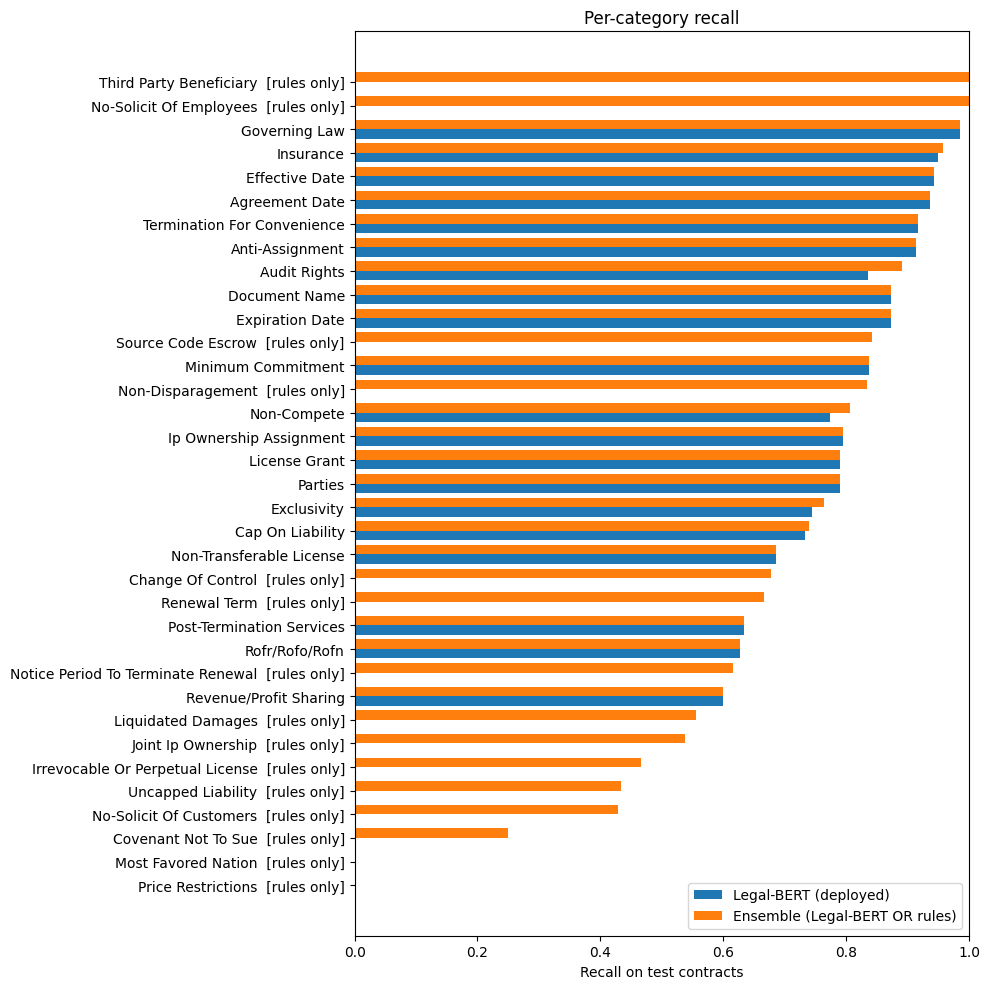

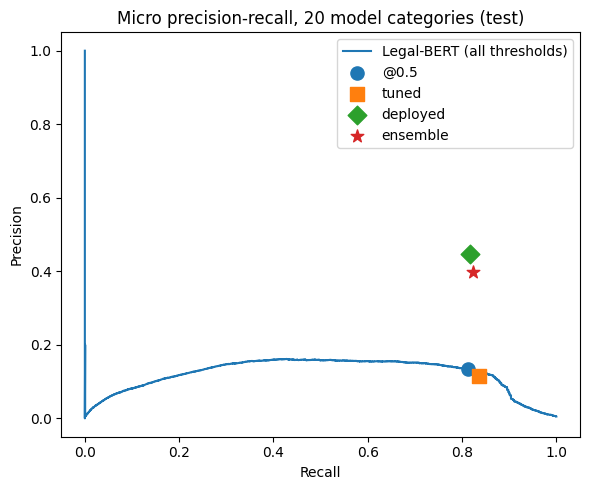

In [40]:
fig, ax = plt.subplots(figsize=(10, 10))
y = np.arange(len(per_cat))
ax.barh(y - 0.2, per_cat['R Legal-BERT'].fillna(0), height=0.4, label='Legal-BERT (deployed)')
ax.barh(y + 0.2, per_cat['R Ensemble'], height=0.4, label='Ensemble (Legal-BERT OR rules)')
ax.set_yticks(y)
ax.set_yticklabels([c + ('  [rules only]' if d == 'rules only' else '') for c, d in zip(per_cat['category'], per_cat['detector'])])
ax.set_xlabel('Recall on test contracts'); ax.set_xlim(0, 1)
ax.legend(loc='lower right'); ax.set_title('Per-category recall')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'recall_per_category.png'), dpi=120); plt.show()

# Micro precision-recall curve with operating points
prec, rec, _ = precision_recall_curve(Y_true[:, has_model].ravel(), probs.ravel())
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(rec, prec, label='Legal-BERT (all thresholds)')
for name, p, m in [('@0.5', pred_05, 'o'), ('tuned', pred_tuned, 's'), ('deployed', pred_deployed, 'D'), ('ensemble', pred_ens, '*')]:
    s = scores(Y_true, p, has_model)
    ax.scatter(s['micro R'], s['micro P'], marker=m, s=90, zorder=3, label=name)
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title(f'Micro precision-recall, {n_model} model categories (test)')
ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'precision_recall.png'), dpi=120); plt.show()

### Headline: important clauses surfaced

In [41]:
gold_any = test_df['labels'].str.len().values > 0
gold_covered = Y_true.any(axis=1)
gold_non_parties = test_df['labels'].apply(lambda ls: any(l != 'Parties' for l in ls)).values
any_rule = test_df['rule_flags'].str.len().values > 0
not_parties = np.array([c != 'Parties' for c in EVAL_CATEGORIES])
surfaced = pred_deployed.any(axis=1) | any_rule
surfaced_raw = pred_tuned.any(axis=1) | any_rule
surfaced_np = pred_deployed[:, not_parties].any(axis=1) | any_rule

def pct(x): return f"{x:.1%}"
def rate(s, g): return pct((s & g).sum() / g.sum())
headline = {
    'important clauses (any CUAD label)': f"{int(gold_any.sum()):,}",
    'surfaced by ensemble, as deployed (any label)': rate(surfaced, gold_any),
    'surfaced by ensemble (labels in a category some detector covers)': rate(surfaced, gold_covered),
    'surfaced, ignoring Parties flags (clauses with a non-Parties label)': rate(surfaced_np, gold_non_parties),
    'surfaced by rules alone (any label)': rate(any_rule, gold_any),
    'surfaced by Legal-BERT alone, deployed (any label)': rate(pred_deployed.any(axis=1), gold_any),
    'share of ALL clauses flagged (reading load), as deployed': pct(surfaced.mean()),
    'share of ALL clauses flagged with raw Parties flags (for comparison)': pct(surfaced_raw.mean()),
}
headline_df = pd.DataFrame(headline.items(), columns=['metric', 'value'])
display(headline_df)

,metric,value
0,important clauses (any CUAD label),"1,524"
1,"surfaced by ensemble, as deployed (any label)",80.3%
2,surfaced by ensemble (labels in a category some detector covers),84.1%
3,"surfaced, ignoring Parties flags (clauses with a non-Parties label)",80.3%
4,surfaced by rules alone (any label),35.5%
5,"surfaced by Legal-BERT alone, deployed (any label)",73.7%
6,"share of ALL clauses flagged (reading load), as deployed",21.8%
7,share of ALL clauses flagged with raw Parties flags (for comparison),63.8%


## 5.2 Error analysis

In [42]:
# Missed clauses in the weakest categories
fn_mask = (Y_true == 1) & (pred_ens == 0)
worst = per_cat[per_cat['support'] >= 5].head(6)['category'].tolist()
for c in worst:
    j = EVAL_IDX[c]
    idx = np.where(fn_mask[:, j])[0]
    det = per_cat.set_index('category').loc[c, 'detector']
    print(f"\n=== {c} ({det}): missed {len(idx)} of {int(Y_true[:, j].sum())} ===")
    for i in idx[:3]:
        top = [k for k in np.argsort(-probs[i]) if CATEGORIES[k] != 'Parties'][:2]
        guess = ', '.join(f"{CATEGORIES[k]} {probs[i, k]:.2f}" for k in top)
        model_p = f"p({c})={probs[i, j]:.2f} (threshold {THRESHOLDS[j]:.2f})" if j < n_model else 'no model head'
        print(f"- {model_p}; rule flags {test_df.loc[i, 'rule_flags'] or 'none'}; model's top non-Parties guesses: {guess}")
        print(f"  \"{test_df.loc[i, 'clause_text'][:300]}\"")


=== Covenant Not To Sue (rules only): missed 9 of 12 ===
- no model head; rule flags none; model's top non-Parties guesses: Anti-Assignment 0.01, License Grant 0.00
  "The Parties acknowledge and affirm their respective rights in and to the relevant trademark and related rights subject to this Agreement and neither Party shall directly or indirectly attack, challenge or impair the title and related rights of the other Party during the Interim Period or any time th"
- no model head; rule flags none; model's top non-Parties guesses: Anti-Assignment 0.01, License Grant 0.00
  "At no time during or after the term of this Agreement shall either party challenge or assist others to challenge the other party's Trademarks or the registration thereof or attempt to register any trademarks, marks or trade names confusingly similar to those of the other party."
- no model head; rule flags none; model's top non-Parties guesses: Anti-Assignment 0.01, Document Name 0.01
  "Notwithstanding any prior t

In [43]:
# Miss rate by clause length
test_df['n_words'] = test_df['clause_text'].str.split().str.len()
test_df['length_bucket'] = pd.cut(test_df['n_words'], [0, 15, 30, 60, 120, 100000], labels=['<=15', '16-30', '31-60', '61-120', '>120'])
pos_rows = Y_true.sum(axis=1) > 0
len_df = pd.DataFrame({
    'bucket': test_df['length_bucket'][pos_rows],
    'labels': Y_true[pos_rows].sum(axis=1),
    'missed': fn_mask[pos_rows].sum(axis=1),
}).groupby('bucket', observed=True).sum()
len_df['miss rate'] = (len_df['missed'] / len_df['labels']).round(3)
display(len_df)

,labels,missed,miss rate
bucket,,,
<=15,107,50,0.467
16-30,385,81,0.210
31-60,670,116,0.173
61-120,453,77,0.170
>120,155,34,0.219


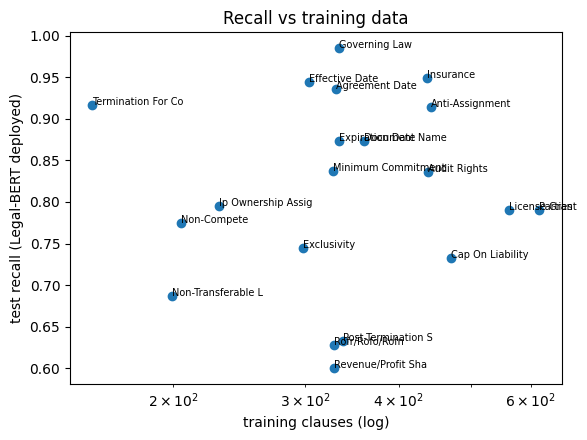

In [44]:
# Recall vs training data
train_counts = clause_df[clause_df['contract_id'].isin(split_ids['train'])]['labels'].explode().value_counts()
per_cat['train examples'] = per_cat['category'].map(train_counts).fillna(0).astype(int)
mc = per_cat[per_cat['detector'] != 'rules only']
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(mc['train examples'], mc['R Legal-BERT'])
for _, r in mc.iterrows():
    ax.annotate(r['category'][:18], (r['train examples'], r['R Legal-BERT']), fontsize=7)
ax.set_xscale('log'); ax.set_xlabel('training clauses (log)'); ax.set_ylabel('test recall (Legal-BERT deployed)')
ax.set_title('Recall vs training data'); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'recall_vs_data.png'), dpi=120); plt.show()

In [45]:
# Most confident false positives (Parties excluded)
fp_mask = (Y_true == 0) & (pred_deployed == 1)
fp_mask[:, EVAL_IDX['Parties']] = False
fp_pairs = sorted(zip(*np.where(fp_mask)), key=lambda ij: -probs[ij])[:8]
for i, j in fp_pairs:
    print(f"- predicted {EVAL_CATEGORIES[j]} ({probs[i, j]:.2f}), gold labels {test_df.loc[i, 'labels']}")
    print(f"  \"{test_df.loc[i, 'clause_text'][:250]}\"")

- predicted Document Name (0.99), gold labels ['Effective Date']
  "Exhibit 10.14(a)

SECOND AMENDED AND RESTATED  EXCLUSIVE AGENCY AND  MARKETING AGREEMENT by and between MONSANTO COMPANY

and

THE SCOTTS COMPANY LLC  Effective as of September 30, 1998





TABLE OF CONTENTS

Article 1 - DEFINITIONS AND RULES OF CON"
- predicted Cap On Liability (0.99), gold labels []
  "Notwithstanding anything to the contrary set forth herein, to the extent permitted by applicable law, in no event shall the Agent be required to contribute an aggregate amount in excess of the aggregate marketing fees to which the Agent is entitled a"
- predicted Document Name (0.99), gold labels ['Agreement Date', 'Parties']
  "Exhibit 7.5



STRATEGIC ALLIANCE AGREEMENT

This Strategic Alliance Agreement is made and entered into this 14 day of June 2006, by and between UTEK Corporation ("UTEK"), a Delaware Corporation, 2109 Palm Avenue, Tampa, Florida 33605, and Manakoa Se"
- predicted Agreement Date (0.99), gold la

## 5.3 Summarisation: ROUGE on BillSum vs Lead-3

In [46]:
# Free memory for BART on the 8 GB Mac
if DEVICE.type != 'cuda':
    classifier.model.to('cpu')
    del clause_df
    gc.collect()
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()

N_EVAL = 50 if DEVICE.type != 'cpu' else 15   # CPU summarisation is slow; raise it if you have time
try:
    from datasets import load_dataset
    billsum = load_dataset('FiscalNote/billsum', split='test').shuffle(seed=42).select(range(N_EVAL))
    docs, refs = billsum['text'], billsum['summary']
    print(f"Loaded {len(docs)} BillSum test documents")
except Exception as e:
    docs, refs = [], []
    print("Could not load BillSum:", e)

Loaded 50 BillSum test documents


In [47]:
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

def rouge_table(preds, refs):
    agg = {k: [] for k in ['rouge1', 'rouge2', 'rougeL']}
    for p, r in zip(preds, refs):
        s = scorer.score(r, p)
        for k in agg:
            agg[k].append(s[k].fmeasure)
    return {k.upper().replace('ROUGE', 'ROUGE-'): round(float(np.mean(v)), 4) for k, v in agg.items()}

rouge_df = None
if docs:
    lead3 = [' '.join(split_into_legal_sentences(d)[:3]) for d in docs]
    def hash_doc(d): return hashlib.md5(d.encode()).hexdigest()
    t0 = time.time()
    sum_bs = 8 if DEVICE.type == 'cuda' else 2
    progress_log = os.path.join(PROJECT_DIR, 'rouge_progress.log')
    # Summaries cached per document
    sum_cache_path = os.path.join(DATA_DIR, 'rouge_summaries_cache.json')
    sum_cache = json.load(open(sum_cache_path)) if os.path.exists(sum_cache_path) else {}
    model_summaries, n_new = [], 0
    for k, d in enumerate(docs, 1):
        key = f"{SUMMARIZER_MODEL}|{hash_doc(d)}"
        if key not in sum_cache:
            sum_cache[key] = summarizer.summarize(d, max_new_tokens=180, min_new_tokens=60, batch_size=sum_bs)
            n_new += 1
            with open(sum_cache_path, 'w') as f:
                json.dump(sum_cache, f)
            if DEVICE.type == 'mps':
                torch.mps.empty_cache()
        model_summaries.append(sum_cache[key])
        with open(progress_log, 'a') as f:
            f.write(f"{time.strftime('%H:%M:%S')} doc {k}/{len(docs)} ({time.time() - t0:.0f}s)\n")
    secs = (time.time() - t0) / len(docs)
    rouge_df = pd.DataFrame({'Lead-3 baseline': rouge_table(lead3, refs),
                             f'{SUMMARIZER_MODEL} (chunked)': rouge_table(model_summaries, refs)}).T
    rouge_df['sec/doc'] = [0.0, round(secs, 2)]
    rouge_df.to_csv(os.path.join(PROJECT_DIR, 'eval_rouge.csv'))
    display(rouge_df)
    print("\nExample\nREFERENCE:", refs[0][:500], "\n\nMODEL:", model_summaries[0][:500])

,ROUGE-1,ROUGE-2,ROUGE-L,sec/doc
Lead-3 baseline,0.2131,0.1244,0.1526,0.0
facebook/bart-large-cnn (chunked),0.4027,0.1906,0.2528,0.0



Example
REFERENCE: HIV Nondiscrimination in Travel and Immigration Act of 2007 - Amends the Immigration and Nationality Act to eliminate the human immunodeficiency virus (HIV) bar to U.S. admission.

Directs the Secretary of Health and Human Services to: (1) convene a panel of public health experts to review immigration policies regarding HIV as a communicable disease of public health significance (and thus a health-related ground for inadmissibility); and (2) make a determination and report to Congress regarding  

MODEL: HIV Nondiscrimination in Travel and Immigration Act of 2007. Applicants for permanent residence and refugee status are required to be tested for HIV infection. If questioned, such applicants may be required to undergo an HIV test. The Act may be cited as the  HIV Nondiscorimination in travel and  immigration act of 2007, which was passed in 2007. The Secretary of Homeland Security may issue a waiver to the HIV prohibition, on a case-by-case basis, only to any HIV-po

## 5.4 Synthetic answer key and review sheets

In [48]:
%%writefile {PROJECT_DIR}/synthetic_check.py
"""
synthetic_check.py
Scores the pipeline's output on the synthetic contracts against synthetic_answer_key.json (see make_test_contracts.py).

For each planted clause:
  caught          the clause it ends up in was flagged at all (shown in Key Details or Red Flags)
  right category  one of the expected categories is among that clause's flags
Benign filler clauses that get flagged are counted as false alarms.
"""

import json
import os
import re

import pandas as pd


def _norm(s):
    return re.sub(r'\s+', ' ', s).strip().lower()


def load_answer_key(sample_dir):
    path = os.path.join(sample_dir, 'synthetic_answer_key.json')
    if not os.path.exists(path):
        return {}
    with open(path) as f:
        return json.load(f)


def check_planted(result, items):
    """result: analyse_text() output for one contract. items: its answer-key entries. Returns one row per item."""
    df = result['clauses']
    clauses = [_norm(t) for t in df['clause_text']]
    rows = []
    for it in items:
        probe = _norm(it['text'])[:60]  # opening words; a planted item may span two sentences
        idx = next((k for k, c in enumerate(clauses) if probe in c), None)
        flags = list(df['all_flags'].iloc[idx]) if idx is not None else []
        source = df['source'].iloc[idx] if idx is not None else ''
        rows.append({
            'note': it['note'],
            'expected': ', '.join(it['expected']) or '(none: benign)',
            'found clause': idx is not None,
            'flags': ', '.join(flags),
            'source': source,
            'benign': it['benign'],
            'caught': bool(flags) and not it['benign'],
            'right category': bool(set(flags) & set(it['expected'])),
            'false alarm': bool(flags) and it['benign'],
        })
    return pd.DataFrame(rows)


def summarise(per_item):
    """per_item: concatenated check_planted rows with a 'contract' column. Returns a one-row-per-contract table."""
    out = []
    for name, g in per_item.groupby('contract', sort=False):
        planted, benign = g[~g['benign']], g[g['benign']]
        out.append({'contract': name, 'planted clauses': len(planted),
                    'caught': int(planted['caught'].sum()), 'right category': int(planted['right category'].sum()),
                    'benign clauses': len(benign), 'false alarms': int(benign['false alarm'].sum()),
                    'not found (splitting problem)': int((~g['found clause']).sum())})
    t = pd.DataFrame(out)
    if len(t):
        total = t.drop(columns='contract').sum()
        total['contract'] = 'TOTAL'
        t = pd.concat([t, total.to_frame().T], ignore_index=True)
        t['catch rate'] = (t['caught'] / t['planted clauses']).astype(float).round(3)
        t['right-category rate'] = (t['right category'] / t['planted clauses']).astype(float).round(3)
    return t

Overwriting /Users/neeharikapai/small_projects/nlpproject/legal_doc_summariser/synthetic_check.py


In [49]:
# Review sheets, then score the synthetic contracts against the answer key
for name, res in contract_results.items():
    sheet = res['clauses'][['section', 'clause_text', 'rule_flags', 'dl_flags', 'all_flags', 'source']].copy()
    sheet['reviewer_risky (y/n)'] = ''
    sheet.to_csv(os.path.join(REVIEW_DIR, os.path.splitext(name)[0] + '_review.csv'), index=False)

from synthetic_check import load_answer_key, check_planted, summarise
synth_parts = []
for name, items in load_answer_key(SAMPLE_DIR).items():
    if name in contract_results:
        r = check_planted(contract_results[name], items)
        r.insert(0, 'contract', name)
        synth_parts.append(r)
if synth_parts:
    synth_items = pd.concat(synth_parts, ignore_index=True)
    synth_df = summarise(synth_items)
    display(synth_df)
    print("Missed, wrong category, or false alarm:")
    display(synth_items[(~synth_items['benign'] & ~synth_items['right category']) | synth_items['false alarm']]
            [['contract', 'note', 'expected', 'flags', 'source']])
else:
    synth_df = pd.DataFrame()
    print("No synthetic contracts found.")

,contract,planted clauses,caught,right category,benign clauses,false alarms,not found (splitting problem),catch rate,right-category rate
0,synthetic_mutual_nda.pdf,13,12,12,2,0,0,0.923,0.923
1,synthetic_residential_lease.pdf,16,15,14,3,1,0,0.938,0.875
2,synthetic_saas_terms.pdf,19,18,17,3,0,0,0.947,0.895
3,TOTAL,48,45,43,8,1,0,0.938,0.896


Missed, wrong category, or false alarm:


,contract,note,expected,flags,source
5,synthetic_mutual_nda.pdf,"liquidated damages, paraphrased (no ""liquidated damages"" phrase)",Liquidated Damages,,
18,synthetic_residential_lease.pdf,benign: rent,(none: benign),Parties,Legal-BERT
19,synthetic_residential_lease.pdf,"unilateral rent increase, paraphrased (hard case)","Unilateral Modification, Price Restrictions",Parties,Legal-BERT
24,synthetic_residential_lease.pdf,"exculpatory clause, paraphrased (hard case)","Cap On Liability, Limitation of Liability",,
36,synthetic_saas_terms.pdf,"auto-renewal, paraphrased (no ""automatically"")",Renewal Term,Parties,Legal-BERT
39,synthetic_saas_terms.pdf,"most-favoured-customer pricing, paraphrased",Most Favored Nation,,


In [50]:
# Real-world recall from the filled-in review sheets
review_rows = []
for f in sorted(os.listdir(REVIEW_DIR)):
    s = pd.read_csv(os.path.join(REVIEW_DIR, f)).fillna('')
    marked = s['reviewer_risky (y/n)'].astype(str).str.lower().str.startswith('y')
    if not marked.any():
        continue
    flagged = s['source'] != ''
    review_rows.append({'contract': f, 'reviewer-risky clauses': int(marked.sum()),
                        'caught by pipeline': int((marked & flagged).sum()),
                        'missed': int((marked & ~flagged).sum()),
                        'real-world recall': round((marked & flagged).sum() / marked.sum(), 3)})
review_df = pd.DataFrame(review_rows)
display(review_df if len(review_df) else "No reviewed sheets yet -- fill in the CSVs in review_sheets/ and re-run this cell.")

'No reviewed sheets yet -- fill in the CSVs in review_sheets/ and re-run this cell.'

## 5.5 Gradio demo

In [51]:
RUN_DEMO = False  # True launches the web demo

if RUN_DEMO:
    import gradio as gr
    classifier.model.to(DEVICE)  # moved to CPU during ROUGE to save memory

    def demo_fn(pdf_file):
        if pdf_file is None:
            return "Upload a PDF contract first."
        path = pdf_file if isinstance(pdf_file, str) else pdf_file.name
        t0 = time.time()
        report, res = summarize_document(path, classifier, summarizer)
        return report + f"\n\n_Processed in {time.time()-t0:.1f}s on {DEVICE}._"

    demo = gr.Interface(
        fn=demo_fn,
        inputs=gr.File(label='Contract PDF', file_types=['.pdf'], type='filepath'),
        outputs=gr.Markdown(label='Report'),
        title='Legal Document Summariser',
        description='Key details, red-flag clauses (rules + fine-tuned Legal-BERT) and an abstractive summary (BART).',
        flagging_mode='never',
    )
    demo.launch(share=IN_COLAB)

## 5.6 Write REPORT.md

In [52]:
def md_table(df, index=True):
    df = df.copy()
    if index:
        df = df.reset_index().rename(columns={'index': 'system'})
    df = df.map(lambda v: f"{v:.3f}" if isinstance(v, (float, np.floating)) and not np.isnan(v) else ('' if isinstance(v, float) else str(v)))
    head = '| ' + ' | '.join(map(str, df.columns)) + ' |'
    sep = '|' + '---|' * len(df.columns)
    return '\n'.join([head, sep] + ['| ' + ' | '.join(r) + ' |' for r in df.values.tolist()])

hist_path = os.path.join(MODEL_DIR, 'training_history.csv')
hist = pd.read_csv(hist_path) if os.path.exists(hist_path) else None
meta = classifier.meta

n_patterns = sum(len(v) for v in RISK_PATTERNS.values())
rules_only = per_cat[per_cat['detector'] == 'rules only']
weakest = per_cat[per_cat['support'] >= 5].head(3)
report = f"""# Legal Document Summariser: Project Report (auto-generated draft)

## 1. Problem
Long legal contracts hide clauses a signer must know about (auto-renewal, one-sided termination, liability caps,
indemnities, non-competes, ...). Missing one is costly, so the system is designed for **high recall** on important
clauses, and it presents them **verbatim** next to a readable abstractive summary.

## 2. System
1. **Ingestion & structure (classical NLP):** pdfplumber/PyMuPDF text extraction; regex heading detection with a context check
   (a heading must start a new block, so wrapped lines of ALL-CAPS clauses are not mistaken for headings); a legal-aware sentence
   splitter that protects abbreviations ("Sec.", "Inc.") and clause numbers ("3.2.1").
2. **Rule layer (classical NLP):** {len(RISK_PATTERNS)} regex risk categories ({n_patterns} patterns), developed on the CUAD
   train contracts and checked on the validation contracts. {len(RULE_CUAD_CATS)} CUAD categories are covered by a rule.
3. **Fine-tuned Legal-BERT (DL):** `{meta['base_model']}` fine-tuned end-to-end on CUAD for multi-label classification over
   the {n_model} most frequent clause categories; {meta.get('epochs')} epochs, lr {meta.get('lr')}, max length {meta['max_len']},
   weighted BCE + negative down-sampling (ratio {meta.get('neg_ratio')}); per-category thresholds tuned for F2 on validation contracts.
   Trained on GPU ({meta.get('device', 'cuda')}). It was trained on the first version of the clause table, whose "Parties" labels were
   noisy, so the pipeline keeps its Parties flag only in a document's first {PARTIES_MAX_CLAUSE_INDEX} clauses (Section 4.4).
4. **Ensemble:** a clause is surfaced if the rules **or** Legal-BERT flag it. Rule names are mapped to CUAD names so a clause caught
   by both detectors appears once, credited to both.
5. **Abstractive summarisation (DL):** `{SUMMARIZER_MODEL}`, section-wise with sentence-boundary chunking, then an overall summary.

## 3. Data
- **CUAD v1**: 510 commercial contracts, 41 lawyer-annotated clause categories. Split **by contract** 70/15/15
  ({len(split_ids['train'])}/{len(split_ids['val'])}/{len(split_ids['test'])} contracts) to avoid leakage. Evaluated against labels derived
  from the answers' character offsets ({len(test_df):,} test clauses).
- **BillSum** (test split, {len(docs)} documents) for summarisation ROUGE.
- **Synthetic contracts:** 3 PDFs (NDA, residential lease, SaaS terms) with planted clauses and an answer key, for an end-to-end check.
- {len([p for p in pdfs if not p.startswith('synthetic_')])} real-world contracts for qualitative testing.

## 4. Results
### 4.1 Clause detection: the {n_model} categories the model learned (test contracts)
{md_table(summary_model)}

### 4.2 The {int((has_model & has_rule).sum())} categories with both a rule and a model head (rules vs model)
{md_table(summary_rulecats)}

### 4.3 All {len(EVAL_CATEGORIES)} evaluated categories, including the {int((~has_model).sum())} only the rules cover
{md_table(summary_all)}

### 4.4 Parties filter
{md_table(parties_df, index=False)}

### 4.5 Headline: important clauses surfaced
{md_table(headline_df, index=False)}

### 4.6 Per-category recall
{md_table(per_cat[['category', 'detector', 'support', 'R Rules', 'R Legal-BERT', 'R Ensemble', 'P Ensemble']], index=False)}

![recall per category](figures/recall_per_category.png)
![precision recall](figures/precision_recall.png)

### 4.7 Summarisation (BillSum, ROUGE F1)
{md_table(rouge_df) if rouge_df is not None else '_not run_'}

### 4.8 End-to-end test on contracts
{('Synthetic contracts scored against the answer key:' + chr(10) + chr(10) + md_table(synth_df, index=False)) if len(synth_df) else '_synthetic contracts not run_'}

{md_table(qual_df, index=False) if len(qual_df) else '_no PDFs run_'}
{md_table(review_df, index=False) if len(review_df) else ''}

{('### 4.9 Training history' + chr(10) + md_table(hist, index=False)) if hist is not None else ''}

## 5. Error analysis (fill in from Part 5, Section 2)
- Weakest categories with at least 5 test clauses: {', '.join(f"{r.category} (R {r['R Ensemble']:.2f}, {r.detector})" for _, r in weakest.iterrows())}.
- Rules-only categories ({len(rules_only)}) have mean recall {rules_only['R Ensemble'].mean():.2f}, against
  {per_cat[per_cat['detector'] != 'rules only']['R Ensemble'].mean():.2f} where Legal-BERT has a head: retraining on all 41 categories is the main fix.
- Miss rate by clause length (evaluation §2b; clauses are truncated at {meta['max_len']} tokens):

{md_table(len_df.reset_index(), index=False)}

- Many high-confidence "false positives" are relevant clauses CUAD simply didn't highlight (label noise).

## 6. Design decisions & limitations
- Extractive red flags + abstractive summary, so a summariser can never silently drop a risky clause.
- Rules cover CUAD categories the classifier has no head for; the classifier catches paraphrases the rules miss.
- The classifier was trained on noisy Parties labels and only the top {n_model} categories (no GPU access to retrain).
- `{SUMMARIZER_MODEL}` is trained on news, not contracts (domain gap; see ROUGE vs Lead-3).
- Heading detection is heuristic and template-dependent; scanned PDFs need OCR first.
- Not legal advice.

## 7. Future work
Retrain Legal-BERT on the corrected labels and all 41 categories; legal-domain summariser (e.g. fine-tune on contract summaries);
longer-context classifier (Longformer / sliding window); OCR support.
"""
with open(os.path.join(PROJECT_DIR, 'REPORT.md'), 'w') as f:
    f.write(report)
print("Wrote", os.path.join(PROJECT_DIR, 'REPORT.md'))
display(Markdown(report))

Wrote /Users/neeharikapai/small_projects/nlpproject/legal_doc_summariser/REPORT.md


# Legal Document Summariser: Project Report (auto-generated draft)

## 1. Problem
Long legal contracts hide clauses a signer must know about (auto-renewal, one-sided termination, liability caps,
indemnities, non-competes, ...). Missing one is costly, so the system is designed for **high recall** on important
clauses, and it presents them **verbatim** next to a readable abstractive summary.

## 2. System
1. **Ingestion & structure (classical NLP):** pdfplumber/PyMuPDF text extraction; regex heading detection with a context check
   (a heading must start a new block, so wrapped lines of ALL-CAPS clauses are not mistaken for headings); a legal-aware sentence
   splitter that protects abbreviations ("Sec.", "Inc.") and clause numbers ("3.2.1").
2. **Rule layer (classical NLP):** 29 regex risk categories (132 patterns), developed on the CUAD
   train contracts and checked on the validation contracts. 23 CUAD categories are covered by a rule.
3. **Fine-tuned Legal-BERT (DL):** `nlpaueb/legal-bert-base-uncased` fine-tuned end-to-end on CUAD for multi-label classification over
   the 20 most frequent clause categories; 3 epochs, lr 2e-05, max length 256,
   weighted BCE + negative down-sampling (ratio 2.0); per-category thresholds tuned for F2 on validation contracts.
   Trained on GPU (cuda). It was trained on the first version of the clause table, whose "Parties" labels were
   noisy, so the pipeline keeps its Parties flag only in a document's first 5 clauses (Section 4.4).
4. **Ensemble:** a clause is surfaced if the rules **or** Legal-BERT flag it. Rule names are mapped to CUAD names so a clause caught
   by both detectors appears once, credited to both.
5. **Abstractive summarisation (DL):** `facebook/bart-large-cnn`, section-wise with sentence-boundary chunking, then an overall summary.

## 3. Data
- **CUAD v1**: 510 commercial contracts, 41 lawyer-annotated clause categories. Split **by contract** 70/15/15
  (357/76/77 contracts) to avoid leakage. Evaluated against labels derived
  from the answers' character offsets (15,004 test clauses).
- **BillSum** (test split, 50 documents) for summarisation ROUGE.
- **Synthetic contracts:** 3 PDFs (NDA, residential lease, SaaS terms) with planted clauses and an answer key, for an end-to-end check.
- 0 real-world contracts for qualitative testing.

## 4. Results
### 4.1 Clause detection: the 20 categories the model learned (test contracts)
| system | macro P | macro R | macro F1 | micro P | micro R | micro F1 |
|---|---|---|---|---|---|---|
| Legal-BERT @0.5 | 0.510 | 0.800 | 0.596 | 0.133 | 0.812 | 0.228 |
| Legal-BERT tuned | 0.471 | 0.822 | 0.568 | 0.115 | 0.836 | 0.203 |
| Legal-BERT deployed | 0.492 | 0.812 | 0.594 | 0.448 | 0.816 | 0.579 |
| Ensemble | 0.439 | 0.818 | 0.552 | 0.399 | 0.823 | 0.537 |

### 4.2 The 8 categories with both a rule and a model head (rules vs model)
| system | macro P | macro R | macro F1 | micro P | micro R | micro F1 |
|---|---|---|---|---|---|---|
| Rules | 0.435 | 0.487 | 0.442 | 0.423 | 0.544 | 0.476 |
| Legal-BERT @0.5 | 0.568 | 0.815 | 0.657 | 0.597 | 0.822 | 0.692 |
| Legal-BERT tuned | 0.540 | 0.833 | 0.645 | 0.575 | 0.839 | 0.683 |
| Legal-BERT deployed | 0.540 | 0.833 | 0.645 | 0.575 | 0.839 | 0.683 |
| Ensemble | 0.409 | 0.848 | 0.540 | 0.413 | 0.857 | 0.558 |

### 4.3 All 35 evaluated categories, including the 15 only the rules cover
| system | macro P | macro R | macro F1 | micro P | micro R | micro F1 |
|---|---|---|---|---|---|---|
| Rules | 0.232 | 0.349 | 0.255 | 0.383 | 0.260 | 0.310 |
| Legal-BERT deployed | 0.281 | 0.464 | 0.339 | 0.448 | 0.723 | 0.553 |
| Ensemble | 0.384 | 0.705 | 0.470 | 0.388 | 0.798 | 0.522 |

### 4.4 Parties filter
| Parties flags | flagged | precision | recall |
|---|---|---|---|
| raw model (threshold 0.05) | 8787 | 0.018 | 0.987 |
| deployed (first 5 clauses of a document) | 288 | 0.431 | 0.790 |

### 4.5 Headline: important clauses surfaced
| metric | value |
|---|---|
| important clauses (any CUAD label) | 1,524 |
| surfaced by ensemble, as deployed (any label) | 80.3% |
| surfaced by ensemble (labels in a category some detector covers) | 84.1% |
| surfaced, ignoring Parties flags (clauses with a non-Parties label) | 80.3% |
| surfaced by rules alone (any label) | 35.5% |
| surfaced by Legal-BERT alone, deployed (any label) | 73.7% |
| share of ALL clauses flagged (reading load), as deployed | 21.8% |
| share of ALL clauses flagged with raw Parties flags (for comparison) | 63.8% |

### 4.6 Per-category recall
| category | detector | support | R Rules | R Legal-BERT | R Ensemble | P Ensemble |
|---|---|---|---|---|---|---|
| Price Restrictions | rules only | 0 | 0.000 |  | 0.000 | 0.000 |
| Most Favored Nation | rules only | 4 | 0.000 |  | 0.000 | 0.000 |
| Covenant Not To Sue | rules only | 12 | 0.250 |  | 0.250 | 0.115 |
| No-Solicit Of Customers | rules only | 7 | 0.429 |  | 0.429 | 0.250 |
| Uncapped Liability | rules only | 30 | 0.433 |  | 0.433 | 0.351 |
| Irrevocable Or Perpetual License | rules only | 15 | 0.467 |  | 0.467 | 1.000 |
| Joint Ip Ownership | rules only | 13 | 0.538 |  | 0.538 | 0.350 |
| Liquidated Damages | rules only | 9 | 0.556 |  | 0.556 | 0.294 |
| Revenue/Profit Sharing | Legal-BERT | 85 |  | 0.600 | 0.600 | 0.486 |
| Notice Period To Terminate Renewal | rules only | 13 | 0.615 |  | 0.615 | 0.471 |
| Rofr/Rofo/Rofn | Legal-BERT | 43 |  | 0.628 | 0.628 | 0.397 |
| Post-Termination Services | Legal-BERT | 60 |  | 0.633 | 0.633 | 0.286 |
| Renewal Term | rules only | 27 | 0.667 |  | 0.667 | 0.450 |
| Change Of Control | rules only | 31 | 0.677 |  | 0.677 | 0.231 |
| Non-Transferable License | Legal-BERT | 67 |  | 0.687 | 0.687 | 0.511 |
| Cap On Liability | Legal-BERT + rules | 127 | 0.346 | 0.732 | 0.740 | 0.534 |
| Exclusivity | Legal-BERT + rules | 51 | 0.275 | 0.745 | 0.765 | 0.181 |
| Parties | Legal-BERT | 157 |  | 0.790 | 0.790 | 0.431 |
| License Grant | Legal-BERT | 119 |  | 0.790 | 0.790 | 0.595 |
| Ip Ownership Assignment | Legal-BERT + rules | 39 | 0.385 | 0.795 | 0.795 | 0.341 |
| Non-Compete | Legal-BERT + rules | 31 | 0.419 | 0.774 | 0.806 | 0.269 |
| Non-Disparagement | rules only | 12 | 0.833 |  | 0.833 | 0.400 |
| Minimum Commitment | Legal-BERT | 49 |  | 0.837 | 0.837 | 0.410 |
| Source Code Escrow | rules only | 19 | 0.842 |  | 0.842 | 0.320 |
| Expiration Date | Legal-BERT | 71 |  | 0.873 | 0.873 | 0.738 |
| Document Name | Legal-BERT | 79 |  | 0.873 | 0.873 | 0.324 |
| Audit Rights | Legal-BERT + rules | 128 | 0.617 | 0.836 | 0.891 | 0.424 |
| Anti-Assignment | Legal-BERT + rules | 93 | 0.624 | 0.914 | 0.914 | 0.607 |
| Termination For Convenience | Legal-BERT + rules | 36 | 0.361 | 0.917 | 0.917 | 0.418 |
| Agreement Date | Legal-BERT | 78 |  | 0.936 | 0.936 | 0.230 |
| Effective Date | Legal-BERT | 71 |  | 0.944 | 0.944 | 0.211 |
| Insurance | Legal-BERT + rules | 118 | 0.873 | 0.949 | 0.958 | 0.496 |
| Governing Law | Legal-BERT | 65 |  | 0.985 | 0.985 | 0.901 |
| No-Solicit Of Employees | rules only | 7 | 1.000 |  | 1.000 | 0.241 |
| Third Party Beneficiary | rules only | 4 | 1.000 |  | 1.000 | 0.167 |

![recall per category](figures/recall_per_category.png)
![precision recall](figures/precision_recall.png)

### 4.7 Summarisation (BillSum, ROUGE F1)
| system | ROUGE-1 | ROUGE-2 | ROUGE-L | sec/doc |
|---|---|---|---|---|
| Lead-3 baseline | 0.213 | 0.124 | 0.153 | 0.000 |
| facebook/bart-large-cnn (chunked) | 0.403 | 0.191 | 0.253 | 0.000 |

### 4.8 End-to-end test on contracts
Synthetic contracts scored against the answer key:

| contract | planted clauses | caught | right category | benign clauses | false alarms | not found (splitting problem) | catch rate | right-category rate |
|---|---|---|---|---|---|---|---|---|
| synthetic_mutual_nda.pdf | 13 | 12 | 12 | 2 | 0 | 0 | 0.923 | 0.923 |
| synthetic_residential_lease.pdf | 16 | 15 | 14 | 3 | 1 | 0 | 0.938 | 0.875 |
| synthetic_saas_terms.pdf | 19 | 18 | 17 | 3 | 0 | 0 | 0.947 | 0.895 |
| TOTAL | 48 | 45 | 43 | 8 | 1 | 0 | 0.938 | 0.896 |

| contract | clauses | sections | flagged | rules only | Legal-BERT only | both | seconds |
|---|---|---|---|---|---|---|---|
| synthetic_mutual_nda.pdf | 19 | 9 | 13 | 6 | 2 | 5 | 14.400 |
| synthetic_residential_lease.pdf | 20 | 8 | 16 | 6 | 5 | 5 | 14.400 |
| synthetic_saas_terms.pdf | 22 | 8 | 18 | 5 | 6 | 7 | 11.800 |


### 4.9 Training history
| epoch | train_loss | val_precision | val_recall | val_f1 | val_f2 | minutes |
|---|---|---|---|---|---|---|
| 1 | 0.175 | 0.502 | 0.742 | 0.585 | 0.663 | 8.753 |
| 2 | 0.054 | 0.496 | 0.808 | 0.602 | 0.704 | 8.536 |
| 3 | 0.036 | 0.556 | 0.778 | 0.637 | 0.710 | 8.693 |

## 5. Error analysis (fill in from Part 5, Section 2)
- Weakest categories with at least 5 test clauses: Covenant Not To Sue (R 0.25, rules only), No-Solicit Of Customers (R 0.43, rules only), Uncapped Liability (R 0.43, rules only).
- Rules-only categories (15) have mean recall 0.55, against
  0.82 where Legal-BERT has a head: retraining on all 41 categories is the main fix.
- Miss rate by clause length (evaluation §2b; clauses are truncated at 256 tokens):

| bucket | labels | missed | miss rate |
|---|---|---|---|
| <=15 | 107 | 50 | 0.467 |
| 16-30 | 385 | 81 | 0.210 |
| 31-60 | 670 | 116 | 0.173 |
| 61-120 | 453 | 77 | 0.170 |
| >120 | 155 | 34 | 0.219 |

- Many high-confidence "false positives" are relevant clauses CUAD simply didn't highlight (label noise).

## 6. Design decisions & limitations
- Extractive red flags + abstractive summary, so a summariser can never silently drop a risky clause.
- Rules cover CUAD categories the classifier has no head for; the classifier catches paraphrases the rules miss.
- The classifier was trained on noisy Parties labels and only the top 20 categories (no GPU access to retrain).
- `facebook/bart-large-cnn` is trained on news, not contracts (domain gap; see ROUGE vs Lead-3).
- Heading detection is heuristic and template-dependent; scanned PDFs need OCR first.
- Not legal advice.

## 7. Future work
Retrain Legal-BERT on the corrected labels and all 41 categories; legal-domain summariser (e.g. fine-tune on contract summaries);
longer-context classifier (Longformer / sliding window); OCR support.


In [53]:
if IN_COLAB:
    archive = shutil.make_archive('/content/legal_doc_summariser_final', 'zip', PROJECT_DIR)
    from google.colab import files
    files.download(archive)